In [1]:
import mne
import copy
import torch
import wandb
import pickle
import hashlib
import pathlib

from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score

from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from scripts.dataset_manager import read_raw_dataset

# Feature extraction

In [2]:
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')
EPOCH_FILTERED_DATASET_NAME = pathlib.Path('data/epoch_dataset_filtered')

def merge_epochs_dict(epochs_dict):
    """Merges the dict of epochs into a single epoch object, preserving subject and session identification in the metadata."""
    all_epochs = []

    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()

            # build/extend metadata with subject + session
            n = len(ep)
            extra = pd.DataFrame(
                {"subject": [subj] * n, "session": [sess] * n},
                index=ep.metadata.index if ep.metadata is not None else range(n),
            )

            if ep.metadata is None:
                ep.metadata = extra
            else:
                # avoid clobbering if these columns already exist
                meta = ep.metadata.copy()
                meta["subject"] = subj
                meta["session"] = sess
                ep.metadata = meta

            all_epochs.append(ep)

    merged = mne.concatenate_epochs(all_epochs)
    return merged

def query_epochs(epochs, query):
    ep = epochs.copy()
    keep_idx = ep.metadata.query(query).index
    mask = ep.metadata.index.isin(keep_idx)
    return ep[mask]

epoch_dict = read_raw_dataset(EPOCH_FILTERED_DATASET_NAME)
epochs = merge_epochs_dict(epoch_dict)
epochs_scaled = epochs.copy()
epochs_scaled.load_data().apply_function(
    lambda x: (x - x.mean()) / (x.std() + 1e-12), channel_wise=True
)

# normal data
filtered_epochs = query_epochs(epochs, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')").copy()

# GAZE as hard negatives
filtered_epochs_gaze = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'GAZE'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_gaze_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'GAZE'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_gaze.metadata.loc[:, 'OriginalEventType'] = filtered_epochs_gaze.metadata.loc[:, 'EventType']
filtered_epochs_gaze.metadata.loc[filtered_epochs_gaze.metadata.PinchType == 'GAZE', 'EventType'] = "NoPinchLog"
filtered_epochs_gaze_scaled.metadata.loc[:, 'OriginalEventType'] = filtered_epochs_gaze_scaled.metadata.loc[:, 'EventType']
filtered_epochs_gaze_scaled.metadata.loc[filtered_epochs_gaze_scaled.metadata.PinchType == 'GAZE', 'EventType'] = "NoPinchLog"

# PINCH_WIZARD_OF_OZ as pinches
filtered_epochs_hinted = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_WIZARD_OF_OZ'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_hinted_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_WIZARD_OF_OZ'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_hinted.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_hinted.metadata.loc[:, 'PinchType']
filtered_epochs_hinted.metadata.loc[filtered_epochs_hinted.metadata.PinchType == 'PINCH_WIZARD_OF_OZ', 'PinchType'] = "PINCH"
filtered_epochs_hinted_scaled.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_hinted_scaled.metadata.loc[:, 'PinchType']
filtered_epochs_hinted_scaled.metadata.loc[filtered_epochs_hinted_scaled.metadata.PinchType == 'PINCH_WIZARD_OF_OZ', 'PinchType'] = "PINCH"

# PINCH_IGNORED as pinches
filtered_epochs_ignored = query_epochs(epochs, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_IGNORED'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_ignored_scaled = query_epochs(epochs_scaled, "((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_IGNORED'))) | (EventType == 'NoPinchLog')").copy()
filtered_epochs_ignored.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_ignored.metadata.loc[:, 'PinchType']
filtered_epochs_ignored.metadata.loc[filtered_epochs_ignored.metadata.PinchType == 'PINCH_IGNORED', 'PinchType'] = "PINCH"
filtered_epochs_ignored_scaled.metadata.loc[:, 'OriginalPinchType'] = filtered_epochs_ignored_scaled.metadata.loc[:, 'PinchType']
filtered_epochs_ignored_scaled.metadata.loc[filtered_epochs_ignored_scaled.metadata.PinchType == 'PINCH_IGNORED', 'PinchType'] = "PINCH"


Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
264 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_2\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
124 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_22\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
185 matching events foun

C:\Users\nicol\AppData\Local\Temp\ipykernel_40876\467793732.py:30: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


### Result caching

Model-training runs below are expensive, so their results are cached on disk in `RESULTS_DIR`, keyed by a run name and annotated with `DATA_VERSION` - a fingerprint of the input dataset (`EPOCH_FILTERED_DATASET_NAME`, the directory `read_raw_dataset` above loads from). If a cached result's `data_version` matches the current one, it is loaded instead of retraining. Set `FORCE_RECOMPUTE_RESULTS = True` (or pass `force=True` to `run_cached`) to ignore the cache and recompute everything.

In [3]:
RESULTS_DIR = pathlib.Path('data/results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FORCE_RECOMPUTE_RESULTS = False  # set True to ignore cached results and recompute everything


def compute_data_version(dataset_path: pathlib.Path) -> str:
    """Fingerprints a dataset directory so cached run results can be invalidated when the
    underlying input data changes. Uses (relative path, size, mtime) per file rather than
    hashing file contents, since the dataset is hundreds of MB."""
    dataset_path = pathlib.Path(dataset_path)
    entries = []
    for f in sorted(dataset_path.rglob('*')):
        if f.is_file():
            stat = f.stat()
            entries.append(f"{f.relative_to(dataset_path).as_posix()}:{stat.st_size}:{int(stat.st_mtime_ns)}")
    return hashlib.sha256("\n".join(entries).encode()).hexdigest()[:16]


DATA_VERSION = compute_data_version(EPOCH_FILTERED_DATASET_NAME)


def run_cached(name: str, compute_fn, data_version: str = None, force: bool = None):
    """Runs `compute_fn()` and caches the result under `name` in RESULTS_DIR, annotated with
    `data_version` (defaults to the global DATA_VERSION). On a later call with the same name
    and data_version, the cached result is loaded instead of recomputing. Pass force=True (or
    set FORCE_RECOMPUTE_RESULTS) to always recompute and overwrite the cache."""
    data_version = DATA_VERSION if data_version is None else data_version
    force = FORCE_RECOMPUTE_RESULTS if force is None else force
    cache_path = RESULTS_DIR / f"{name}.pkl"

    if not force and cache_path.exists():
        with open(cache_path, "rb") as fh:
            cached = pickle.load(fh)
        if cached.get("data_version") == data_version:
            print(f"[{name}] loaded cached result (data_version={data_version})")
            return cached["result"]
        print(f"[{name}] cached data_version={cached.get('data_version')} != {data_version}, recomputing")
    else:
        print(f"[{name}] {'forced recompute' if force else 'no cache found'}, running...")

    result = compute_fn()
    with open(cache_path, "wb") as fh:
        pickle.dump({"data_version": data_version, "result": result}, fh)
    return result


# Model training & inference

## Random Forest

Input:

--------------------------------------------------------------------------
FILTERING AND BASELINE ARE PARADIGM-SPECIFIC
--------------------------------------------------------------------------

```
  paradigm   high-pass      low-pass   epoch          baseline
  --------   -----------    --------   ------------   -------------------------
  MI         0.5-4 Hz       40 Hz      0.5 .. 3.5 s   none (log-power handles it)
  P300       0.1-0.5 Hz     20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
  SPN        <= 0.05 Hz !   20-30 Hz   -2.0 .. 0.5 s  cue-locked, NOT -0.2..0 s !
  ErrP       0.1-1 Hz       20 Hz      -0.2 .. 0.8 s  -0.2 .. 0 s
```

### Experiment tracking (Weights & Biases)

Every model-training run below logs its config, training curves and test metrics to W&B. `wandb_start_run` / `wandb_log_test_results` / `wandb_finish_run` are model-agnostic — `train_eegnet` already uses them, and future models (Random Forest, Conformer, ...) should reuse the same three helpers instead of duplicating logging code.

In [4]:
WANDB_PROJECT = "eeg-pinch-classification"

wandb.login()


def wandb_start_run(model_name: str, run_name: Optional[str] = None, config: Optional[dict] = None, group: Optional[str] = None, tags: Optional[list[str]] = None, enabled: bool = True):
    """Start a W&B run for one model-training run, shared across model types.

    `model_name` (e.g. "EEGNet", "RandomForest", "Conformer") is stored in the config
    and used as the default group, so runs from different models stay comparable in
    the same project. Set enabled=False to skip tracking (e.g. quick local debugging).
    """
    if not enabled:
        return None
    return wandb.init(
        project=WANDB_PROJECT,
        group=group or model_name,
        job_type=model_name,
        name=run_name,
        tags=[model_name, *(tags or [])],
        config={"model": model_name, **(config or {})},
        reinit="finish_previous",  # auto-finish a dangling run, e.g. after a KeyboardInterrupt
    )


def wandb_log_test_results(run, *, test_accuracy: float, y_true, y_pred, classes, test_loss: Optional[float] = None, extra: Optional[dict] = None):
    """Log final test metrics + confusion matrix. Call once per run, before wandb_finish_run."""
    if run is None:
        return
    summary = {"test/accuracy": test_accuracy, **(extra or {})}
    if test_loss is not None:
        summary["test/loss"] = test_loss
    run.summary.update(summary)
    run.log({
        "test/confusion_matrix": wandb.plot.confusion_matrix(
            preds=[int(p) for p in y_pred],
            y_true=[int(t) for t in y_true],
            class_names=[str(c) for c in classes],
        )
    })


def wandb_finish_run(run):
    if run is not None:
        run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## EEGNet

This is an implementation of EEGNet according to the original paper (Lawhern et al., 2018) in PyTorch.

Input: The EEGNet takes the raw measurements as inputs.

In [5]:
# region EEGNet

# --------------------------------------------------------------------------- #
# Layers with Keras-style max-norm weight constraints
# --------------------------------------------------------------------------- #
class ConstrainedConv2d(nn.Conv2d):
    """Conv2d whose per-filter L2 weight norm is clipped, like Keras max_norm."""

    def __init__(self, *args, max_norm: float = 1.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.max_norm = max_norm

    def forward(self, x):
        with torch.no_grad():
            self.weight.copy_(torch.renorm(self.weight, p=2, dim=0, maxnorm=self.max_norm))
        return super().forward(x)


class ConstrainedLinear(nn.Linear):
    """Linear layer with max-norm constraint on each output unit's weights."""

    def __init__(self, *args, max_norm: float = 0.25, **kwargs):
        super().__init__(*args, **kwargs)
        self.max_norm = max_norm

    def forward(self, x):
        with torch.no_grad():
            self.weight.copy_(torch.renorm(self.weight, p=2, dim=0, maxnorm=self.max_norm))
        return super().forward(x)


# --------------------------------------------------------------------------- #
# The network
# --------------------------------------------------------------------------- #
class EEGNet(nn.Module):
    """
    Parameters
    ----------
    n_classes   : number of output classes
    n_chans     : number of EEG channels C
    n_samples   : number of time samples T per epoch
    kern_length : length of the temporal filters. The paper uses half the
                  sampling rate (64 samples @ 128 Hz) so the filters cover 500 ms.
    F1, D, F2   : temporal filters, spatial filters per temporal filter,
                  pointwise filters. The paper's default is F1=8, D=2, F2=F1*D=16.
    dropout     : 0.25 for within-subject (few trials), 0.5 for cross-subject.
    dropout_type: 'Dropout' or 'SpatialDropout2D' (nn.Dropout2d).
    """

    def __init__(self, n_classes: int, n_chans: int, n_samples: int, kern_length: int = 64, F1: int = 8, D: int = 2, F2: Optional[int] = None, dropout: float = 0.25, dropout_type: str = "Dropout"):
        super().__init__()
        F2 = F1 * D if F2 is None else F2

        if dropout_type == "SpatialDropout2D":
            drop = lambda: nn.Dropout2d(dropout)  # noqa: E731
        elif dropout_type == "Dropout":
            drop = lambda: nn.Dropout(dropout)  # noqa: E731
        else:
            raise ValueError("dropout_type must be 'Dropout' or 'SpatialDropout2D'")

        # ---- Block 1: temporal convolution + depthwise spatial filtering ----
        self.block1 = nn.Sequential(
            nn.Conv2d(1, F1, (1, kern_length), padding="same", bias=False),
            nn.BatchNorm2d(F1),
            ConstrainedConv2d(F1, F1 * D, (n_chans, 1), groups=F1, bias=False, max_norm=1.0),
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),
            drop(),
        )

        # ---- Block 2: separable convolution (depthwise then pointwise) ----
        self.block2 = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding="same", groups=F1 * D, bias=False),
            nn.Conv2d(F1 * D, F2, (1, 1), bias=False),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            drop(),
        )

        # ---- Classifier ----
        with torch.no_grad():
            dummy = torch.zeros(1, 1, n_chans, n_samples)
            n_features = self.block2(self.block1(dummy)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            ConstrainedLinear(n_features, n_classes, max_norm=0.25),
        )

    def forward(self, x):
        # x: (batch, 1, n_chans, n_samples) -> logits (batch, n_classes)
        return self.classifier(self.block2(self.block1(x)))


# --------------------------------------------------------------------------- #
# Small helpers
# --------------------------------------------------------------------------- #
def _to_array(X) -> np.ndarray:
    """Accept an MNE Epochs object or an array of shape (n_trials, C, T)."""
    if hasattr(X, "get_data"):          # mne.Epochs / EpochsArray
        X = X.get_data()
    X = np.asarray(X, dtype=np.float32)
    if X.ndim != 3:
        raise ValueError(f"Expected epochs of shape (n_trials, n_chans, n_samples), got {X.shape}")
    return X


def _to_labels(y) -> np.ndarray:
    if hasattr(y, "events"):            # someone passed Epochs as the label source
        y = y.events[:, 2]
    return np.asarray(y).ravel()


def _stratified_split(y: np.ndarray, frac: float, rng: np.random.Generator):
    """Return (train_idx, val_idx) keeping class proportions."""
    train_idx, val_idx = [], []
    for cls in np.unique(y):
        idx = np.flatnonzero(y == cls)
        rng.shuffle(idx)
        n_val = max(1, int(round(frac * len(idx)))) if len(idx) > 1 else 0
        val_idx.append(idx[:n_val])
        train_idx.append(idx[n_val:])
    return np.concatenate(train_idx), np.concatenate(val_idx)


@torch.no_grad()
def _evaluate(model, loader, criterion, device):
    model.eval()
    loss_sum, n, logits_all = 0.0, 0, []
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        loss_sum += criterion(logits, yb).item() * len(xb)
        n += len(xb)
        logits_all.append(logits.cpu())
    logits_all = torch.cat(logits_all)
    y_true = torch.cat([yb for _, yb in loader])
    acc = (logits_all.argmax(1) == y_true).float().mean().item()
    return loss_sum / n, acc, logits_all


# --------------------------------------------------------------------------- #
# Main entry point
# --------------------------------------------------------------------------- #
def train_eegnet(X_train, y_train, X_test, y_test, *, sfreq: float = 300.0, kern_length: Optional[int] = None,
    F1: int = 8, D: int = 2, F2: Optional[int] = None,
    dropout: float = 0.25, dropout_type: str = "Dropout",
    n_epochs: int = 100, batch_size: int = 256, lr: float = 3e-3,
    validation_split: float = 0.2, class_weights: bool = True,
    scale: str | float = "auto", device: Optional[str] = None, seed: int = 42, verbose: bool = True,
    run_name: Optional[str] = None, wandb_group: Optional[str] = None,
    wandb_tags: Optional[list[str]] = None, log_wandb: bool = True,
):
    """
    Train and test EEGNet on epoched EEG data.

    X_train / X_test : (n_trials, n_chans, n_samples) arrays or MNE Epochs.
    y_train / y_test : (n_trials,) labels (ints or strings).

    sfreq            : sampling rate, used to set kern_length = sfreq // 2 as in the paper.
    validation_split : fraction of the training epochs held out to pick the best
                       weights (the paper selects the checkpoint with lowest val loss).
                       Set to 0 to train on everything and keep the last epoch.
    scale            : 'auto' converts volts to microvolts when the data looks like
                       volts; pass a float to multiply by it, or 1.0 to leave as is.
    run_name / wandb_group / wandb_tags : forwarded to wandb_start_run (see above);
                       every call logs to Weights & Biases unless log_wandb=False.

    Returns a dict with the trained model, per-epoch history, test accuracy,
    predictions, probabilities and the confusion matrix.
    """
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    torch.backends.cudnn.benchmark = True

    # ---- data preparation -------------------------------------------------
    Xtr, Xte = _to_array(X_train), _to_array(X_test)
    ytr, yte = _to_labels(y_train), _to_labels(y_test)
    if Xtr.shape[1:] != Xte.shape[1:]:
        raise ValueError(f"Train/test epochs differ in shape: {Xtr.shape[1:]} vs {Xte.shape[1:]}")
    if len(Xtr) != len(ytr) or len(Xte) != len(yte):
        raise ValueError("Number of epochs and number of labels do not match")

    if scale == "auto":
        factor = 1e6 if np.abs(Xtr).max() < 1e-2 else 1.0  # volts -> microvolts
    else:
        factor = float(scale)
    Xtr, Xte = Xtr * factor, Xte * factor

    classes = np.unique(ytr)
    lut = {c: i for i, c in enumerate(classes)}
    if not set(np.unique(yte)).issubset(lut):
        raise ValueError("Test set contains labels not present in the training set")
    ytr_i = np.array([lut[c] for c in ytr], dtype=np.int64)
    yte_i = np.array([lut[c] for c in yte], dtype=np.int64)

    n_trials, n_chans, n_samples = Xtr.shape
    kern_length = int(sfreq // 2) if kern_length is None else int(kern_length)

    # add the singleton "image channel": (N, 1, C, T)
    Xtr_t = torch.from_numpy(Xtr).float().unsqueeze(1)
    Xte_t = torch.from_numpy(Xte).float().unsqueeze(1)
    ytr_t = torch.from_numpy(ytr_i)
    yte_t = torch.from_numpy(yte_i)

    if validation_split and validation_split > 0:
        tr_idx, va_idx = _stratified_split(ytr_i, validation_split, rng)
    else:
        tr_idx, va_idx = np.arange(n_trials), np.array([], dtype=int)

    train_loader = DataLoader(
        TensorDataset(Xtr_t[tr_idx], ytr_t[tr_idx]), batch_size=batch_size, shuffle=True, pin_memory=True
    )
    val_loader = (
        DataLoader(TensorDataset(Xtr_t[va_idx], ytr_t[va_idx]), batch_size=256, pin_memory=True)
        if len(va_idx) else None
    )
    test_loader = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=256, pin_memory=True)

    # ---- model ------------------------------------------------------------
    model = EEGNet( n_classes=len(classes), n_chans=n_chans, n_samples=n_samples, kern_length=kern_length, F1=F1, D=D, F2=F2, dropout=dropout, dropout_type=dropout_type,).to(device)
    n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)

    if class_weights:
        counts = np.bincount(ytr_i[tr_idx], minlength=len(classes)).astype(np.float64)
        w = torch.tensor(counts.sum() / (len(classes) * np.maximum(counts, 1)), dtype=torch.float32)
        criterion = nn.CrossEntropyLoss(weight=w.to(device))
    else:
        criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if verbose:
        print(f"EEGNet-{F1},{D} | {n_chans} ch x {n_samples} samples | "
              f"{len(classes)} classes | {n_par} trainable params | device={device}")
        if factor != 1.0:
            print(f"Scaled inputs by {factor:g} (volts -> microvolts)")

    wb_run = wandb_start_run(
        "EEGNet", run_name,
        config=dict(
            F1=F1, D=D, F2=F2 or F1 * D, kern_length=kern_length,
            dropout=dropout, dropout_type=dropout_type,
            n_epochs=n_epochs, batch_size=batch_size, lr=lr,
            validation_split=validation_split, class_weights=class_weights,
            scale=factor, sfreq=sfreq, seed=seed,
            n_chans=n_chans, n_samples=n_samples, n_classes=len(classes),
            n_train=len(tr_idx), n_val=len(va_idx), n_test=len(Xte),
            n_params=n_par, device=str(device),
        ),
        group=wandb_group, tags=wandb_tags, enabled=log_wandb,
    )

    try:
        # ---- training loop --------------------------------------------------
        history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
        best_val, best_state = np.inf, copy.deepcopy(model.state_dict())

        for epoch in range(1, n_epochs + 1):
            model.train()
            run_loss, correct, seen = 0.0, 0, 0
            for xb, yb in train_loader:
                xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
                optimizer.zero_grad()
                logits = model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()

                run_loss += loss.item() * len(xb)
                correct += (logits.argmax(1) == yb).sum().item()
                seen += len(xb)

            history["loss"].append(run_loss / seen)
            history["acc"].append(correct / seen)
            epoch_metrics = {"train/loss": history["loss"][-1], "train/acc": history["acc"][-1]}

            if val_loader is not None:
                v_loss, v_acc, _ = _evaluate(model, val_loader, criterion, device)
                history["val_loss"].append(v_loss)
                history["val_acc"].append(v_acc)
                epoch_metrics["val/loss"] = v_loss
                epoch_metrics["val/acc"] = v_acc
                if v_loss < best_val:
                    best_val = v_loss
                    best_state = copy.deepcopy(model.state_dict())
            if wb_run is not None:
                wb_run.log(epoch_metrics, step=epoch)
            if verbose and (epoch % 10 == 0 or epoch == 1):
                msg = f"epoch {epoch:4d}/{n_epochs}  loss {history['loss'][-1]:.4f}  acc {history['acc'][-1]:.3f}"
                if val_loader is not None:
                    msg += f"  val_loss {history['val_loss'][-1]:.4f}  val_acc {history['val_acc'][-1]:.3f}"
                print(msg)

        if val_loader is not None:
            model.load_state_dict(best_state)  # restore best-validation weights

        # ---- test -----------------------------------------------------------
        test_loss, test_acc, logits = _evaluate(model, test_loader, criterion, device)
        proba = torch.softmax(logits, dim=1).numpy()
        y_pred_i = proba.argmax(1)

        cm = np.zeros((len(classes), len(classes)), dtype=int)
        for t, p in zip(yte_i, y_pred_i):
            cm[t, p] += 1

        if verbose:
            print(f"\nTest loss {test_loss:.4f} | test accuracy {test_acc:.4f}")
            print("Confusion matrix (rows = true, cols = predicted):")
            print(cm)

        wandb_log_test_results(
            wb_run, test_accuracy=test_acc, test_loss=test_loss,
            y_true=yte_i, y_pred=y_pred_i, classes=classes,
        )
    finally:
        wandb_finish_run(wb_run)

    return {
        "model": model,
        "history": history,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "y_pred": classes[y_pred_i],
        "y_proba": proba,
        "classes": classes,
        "confusion_matrix": cm,
    }

def _get_history_dict(history):
    """Support Keras History objects or plain dicts of lists."""
    return history.history if hasattr(history, "history") else history

def _chance_level(result):
    """
    Estimate the baseline accuracy using the majority-class baseline.
    """
    cm = np.asarray(result["confusion_matrix"])
    true_class_counts = cm.sum(axis=1)  # rows = true labels
    total = true_class_counts.sum()
    return true_class_counts.max() / total


def plot_run(result, run_name="run", save_path=None):
    """Plot loss/accuracy curves and confusion matrix for a single run."""
    hist = _get_history_dict(result["history"])
    n_epochs = len(next(iter(hist.values())))
    epochs = range(1, n_epochs + 1)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(
        f"{run_name} — test acc: {result['test_accuracy']:.3f}, "
        f"test loss: {result['test_loss']:.3f}"
    )

    # Loss curves
    ax = axes[0]
    if "loss" in hist:
        ax.plot(epochs, hist["loss"], label="train")
    if "val_loss" in hist:
        ax.plot(epochs, hist["val_loss"], label="val")
    ax.set_title("Loss")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Accuracy curves
    ax = axes[1]
    acc_key = "accuracy" if "accuracy" in hist else "acc"
    val_acc_key = "val_accuracy" if "val_accuracy" in hist else "val_acc"
    if acc_key in hist:
        ax.plot(epochs, hist[acc_key], label="train")
    if val_acc_key in hist:
        ax.plot(epochs, hist[val_acc_key], label="val")

    chance = _chance_level(result)
    ax.axhline(
        chance, color="gray", linestyle="--", linewidth=1.5,
        label=f"chance ({chance:.2f})",
    )

    ax.set_title("Accuracy")
    ax.set_xlabel("Epoch")
    ax.legend()

    # Confusion matrix
    ax = axes[2]
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=result["classes"],
    )
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("Confusion matrix")

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig

# endregion

### Comparing cross subject vs cross session

In [6]:
def classify_general(data):
    X_train_idx, X_test_idx, y_train, y_test = train_test_split(np.arange(len(data)), data.metadata.EventType, test_size=.2)
    X_train, X_test = data[X_train_idx], data[X_test_idx]

    return train_eegnet(X_train, y_train, X_test, y_test, run_name="eegnet-general", wandb_group="EEGNet"), X_test.metadata

def classify_cross_subject(data, leave_out='', ignore=''):
    train_subjects, test_subjects = train_test_split(data.metadata["subject"].unique().tolist())
    if leave_out != '':
        train_subjects = data.metadata["subject"].unique().tolist()
        train_subjects.remove(leave_out)
        test_subjects = [leave_out]
    if ignore != '':
        train_subjects.remove(ignore)

    print(f"{len(train_subjects)} train subjects, {len(test_subjects)} test subjects")

    train_epochs = query_epochs(data, f"subject in {train_subjects}")
    test_epochs = query_epochs(data, f"subject in {test_subjects}")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_subject", wandb_group="EEGNet", n_epochs=150), test_epochs.metadata

def classify_cross_session(data):
    train_epochs = query_epochs(data, f"session == 'session_1'")
    test_epochs = query_epochs(data, f"session == 'session_2'")

    return train_eegnet(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, run_name="eegnet-cross_session", wandb_group="EEGNet", n_epochs=100), test_epochs.metadata

def classify_leave_one_out(data):
    results = {}
    for subject in data.metadata["subject"].unique().tolist():
        result, meta = classify_cross_subject(data, leave_out=subject)
        results[subject] = {
            "result": result,
            "test_metadata": meta
        }
    return results

def classify_leave_one_out_and_test_others(data):
    results = {}
    subjects = data.metadata["subject"].unique().tolist()
    for s in subjects:
        results[s] = {}
        for t in subjects:
            if s == t:
                continue
            result, meta = classify_cross_subject(data, leave_out=s, ignore=t)
            results[s][t] = {
                "result": result,
                "test_metadata": meta
            }
    return results

results_general, results_general_meta = run_cached(
    "results_general", lambda: classify_general(filtered_epochs_scaled)
)
results_cross_subject, results_cross_subject_meta = run_cached(
    "results_cross_subject", lambda: classify_cross_subject(filtered_epochs_scaled, leave_out='subject_32')
)
results_cross_session, results_cross_session_meta = run_cached(
    "results_cross_session", lambda: classify_cross_session(filtered_epochs_scaled)
)
results_leave_one_out = run_cached(
    "results_leave_one_out", lambda: classify_leave_one_out(filtered_epochs_scaled)
)
results_leave_one_out1 = run_cached(
    "results_leave_one_out1", lambda: classify_leave_one_out(filtered_epochs_gaze_scaled)
)
results_leave_one_out2 = run_cached(
    "results_leave_one_out2", lambda: classify_leave_one_out(filtered_epochs_hinted_scaled)
)
results_leave_one_out3 = run_cached(
    "results_leave_one_out3", lambda: classify_leave_one_out(filtered_epochs_ignored_scaled)
)
classify_leave_one_out4 = run_cached(
    "classify_leave_one_out4", lambda: classify_leave_one_out_and_test_others(filtered_epochs_scaled)
)

[results_general] forced recompute, running...


C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\torch\nn\modules\conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1105.)
  return F.conv2d(


EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run gz1lbufa
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260919_163704-gz1lbufa
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-general
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/gz1lbufa


epoch    1/100  loss 0.6926  acc 0.544  val_loss 0.6864  val_acc 0.565
epoch   10/100  loss 0.6135  acc 0.663  val_loss 0.6401  val_acc 0.633
epoch   20/100  loss 0.5814  acc 0.700  val_loss 0.6377  val_acc 0.640
epoch   30/100  loss 0.5603  acc 0.702  val_loss 0.6362  val_acc 0.660
epoch   40/100  loss 0.5466  acc 0.728  val_loss 0.6383  val_acc 0.653
epoch   50/100  loss 0.5237  acc 0.751  val_loss 0.6422  val_acc 0.649
epoch   60/100  loss 0.5186  acc 0.745  val_loss 0.6523  val_acc 0.629
epoch   70/100  loss 0.5118  acc 0.746  val_loss 0.6463  val_acc 0.663
epoch   80/100  loss 0.5039  acc 0.750  val_loss 0.6502  val_acc 0.661
epoch   90/100  loss 0.4812  acc 0.760  val_loss 0.6447  val_acc 0.666
epoch  100/100  loss 0.4851  acc 0.766  val_loss 0.6375  val_acc 0.683

Test loss 0.6373 | test accuracy 0.6485
Confusion matrix (rows = true, cols = predicted):
[[312 144]
 [165 258]]


...

wandb: updating run metadata; uploading artifact run-ylnb6wrq-testconfusion_matrix_table-jPkx0w
wandb: uploading artifact run-ylnb6wrq-testconfusion_matrix_table-jPkx0w
wandb: uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 127-149, summary
wandb: 
wandb: Run history:
wandb:  train/acc ▁▂▃▃▃▅▅▅▅▆▆▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇██▇███▇████▇██
wandb: train/loss █▇▇▆▅▅▅▄▄▄▄▄▄▄▄▃▄▃▃▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁
wandb:    val/acc ▁▂▂▃▄▅▄▄▄▅▄▅▄▄▆▆▅▆▅▇▇█▅▆▆▇▆▇▇▇▇▇▇█▇▇▇▇▇▇
wandb:   val/loss ▅▄▂▄▄▄█▄▄▆▅█▆▅▄▄▆▂▃▂▅▁▃▂▂▁▃▅▃▃▅▂▂▃▂▃▂▅▂▂
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.6044
wandb:     test/loss 0.83061
wandb:     train/acc 0.79242
wandb:    train/loss 0.44042
wandb:       val/acc 0.66667
wandb:      val/loss 0.62605
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/ylnb6wrq
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb: Synced 4 W&B file(s), 1 media file(

12 train subjects, 1 test subjects
EEGNet-8,2 | 20 ch x 601 samples | 2 classes | 2690 trainable params | device=cuda


wandb: setting up run oqs3kg5r
wandb: Tracking run with wandb version 0.30.0
wandb: Run data is saved locally in C:\Users\nicol\github\VIBE\DataAnalysis\wandb\run-20260919_204541-oqs3kg5r
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run eegnet-cross_subject
wandb:  View project at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification
wandb:  View run at https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/oqs3kg5r


epoch    1/150  loss 0.6932  acc 0.523  val_loss 0.6842  val_acc 0.566
epoch   10/150  loss 0.6014  acc 0.670  val_loss 0.6522  val_acc 0.628
epoch   20/150  loss 0.5752  acc 0.709  val_loss 0.6518  val_acc 0.645
epoch   30/150  loss 0.5533  acc 0.724  val_loss 0.6433  val_acc 0.633
epoch   40/150  loss 0.5384  acc 0.728  val_loss 0.6505  val_acc 0.647
epoch   50/150  loss 0.5253  acc 0.747  val_loss 0.6510  val_acc 0.655
epoch   60/150  loss 0.5160  acc 0.745  val_loss 0.6525  val_acc 0.656
epoch   70/150  loss 0.5091  acc 0.754  val_loss 0.6500  val_acc 0.660
epoch   80/150  loss 0.4995  acc 0.758  val_loss 0.6613  val_acc 0.644
epoch   90/150  loss 0.4922  acc 0.767  val_loss 0.6521  val_acc 0.658
epoch  100/150  loss 0.4908  acc 0.766  val_loss 0.6566  val_acc 0.644
epoch  110/150  loss 0.4924  acc 0.761  val_loss 0.6390  val_acc 0.655
epoch  120/150  loss 0.4877  acc 0.756  val_loss 0.6595  val_acc 0.647
epoch  130/150  loss 0.4787  acc 0.774  val_loss 0.6548  val_acc 0.644
epoch 

wandb: updating run metadata; uploading artifact run-oqs3kg5r-testconfusion_matrix_table-2YdQdA
wandb: uploading artifact run-oqs3kg5r-testconfusion_matrix_table-2YdQdA
wandb: uploading config.yaml; uploading media\table\test\confusion_matrix_table_150_1b8d87040ec4b73f5519.table.json
wandb: uploading history steps 126-149, summary
wandb: 
wandb: Run history:
wandb:  train/acc ▁▁▃▃▃▄▅▅▅▆▆▆▆▆▇▇▆▇▇▇▇▇▇▇▇█▇▇▇▇▇▇█████▇▇█
wandb: train/loss █▇▆▆▆▅▅▅▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▂▂▁▂▁▁▁▂▁▁▁▁
wandb:    val/acc ▁▃▅▅▆▅▃▃▃▅█▇▇▆▇▆▅▆▆▇▇▄▄▅▆█▅▆▆▇▅▇▇▅█▇▇▆▅▆
wandb:   val/loss █▄▄▃▃▃▄▃▃▃▃▃▃▃▃▄▄▃▃▄▄▃▄▃▂▅▃▃▄▆▃▄▃▂▃▄▃▁▂▃
wandb: 
wandb: Run summary:
wandb: test/accuracy 0.56044
wandb:     test/loss 0.81423
wandb:     train/acc 0.76769
wandb:    train/loss 0.47987
wandb:       val/acc 0.64005
wandb:      val/loss 0.66326
wandb: 
wandb:  View run eegnet-cross_subject at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch-classification/runs/oqs3kg5r
wandb:  View project at: https://wandb.ai/nbaeriswyl-eth-z-rich/eeg-pinch

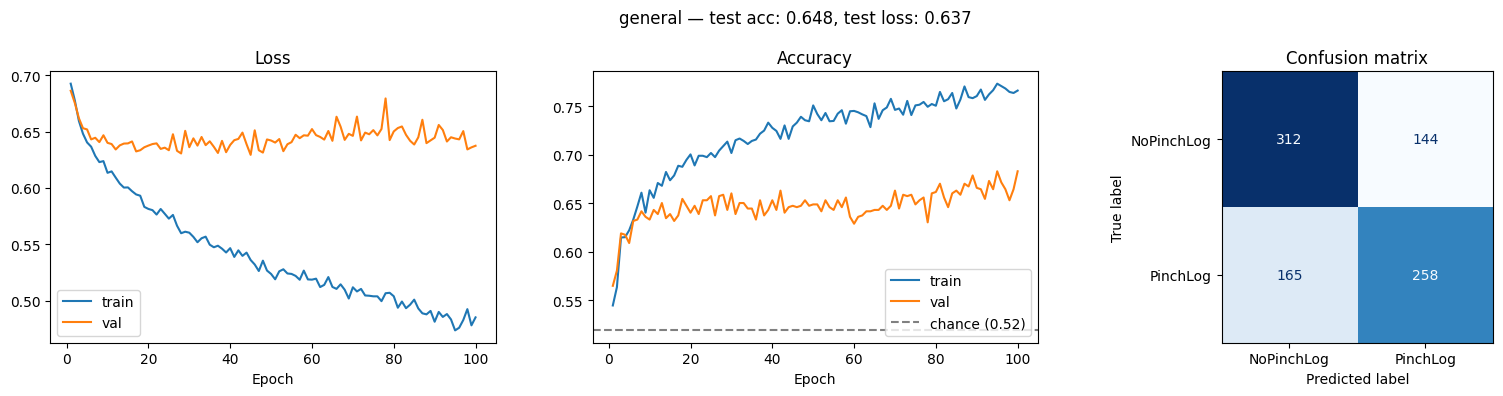

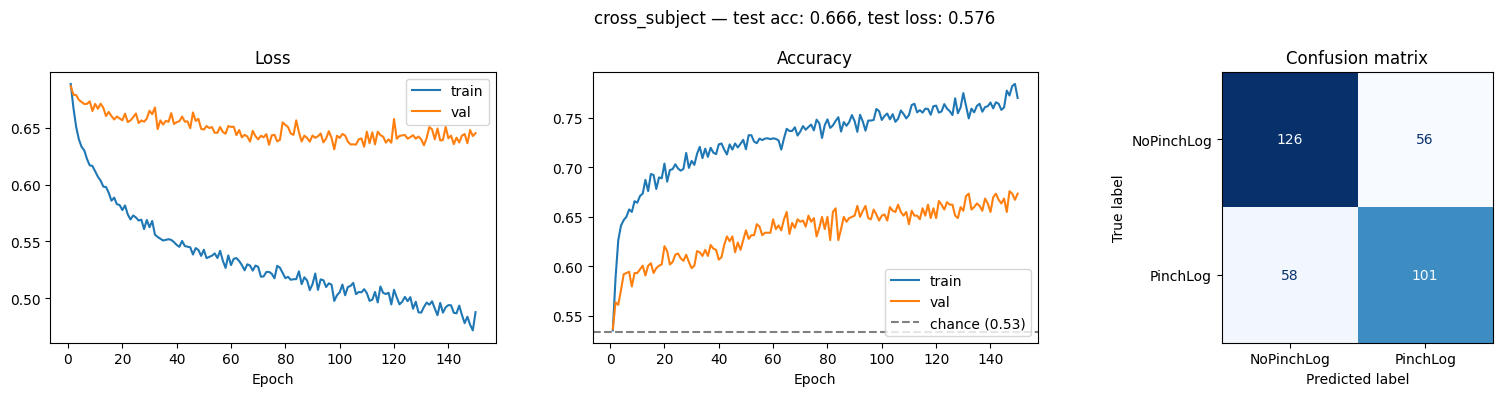

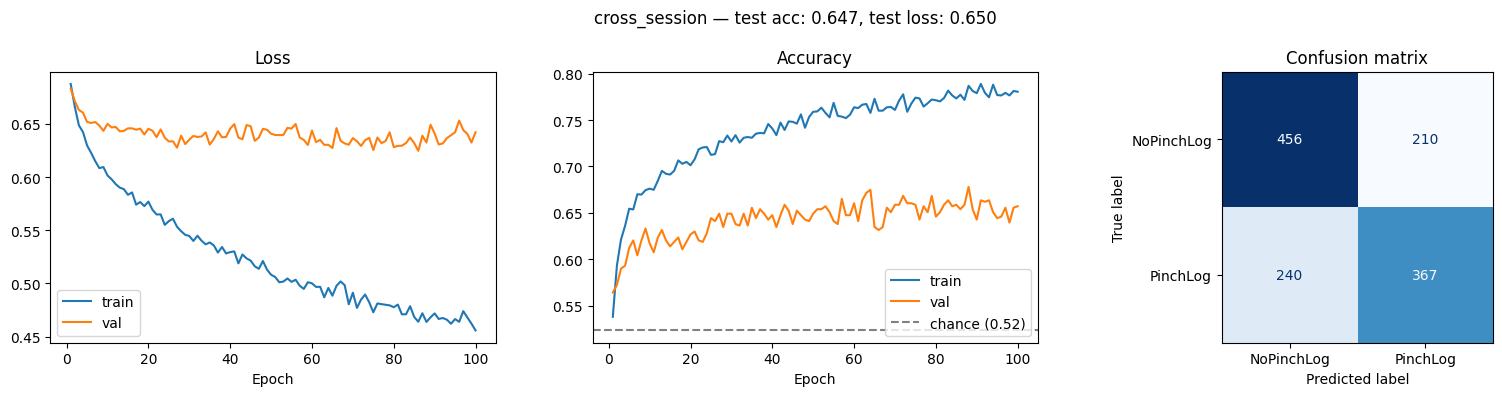

In [7]:
_ = plot_run(results_general, run_name="general")
_ = plot_run(results_cross_subject, run_name="cross_subject")
_ = plot_run(results_cross_session, run_name="cross_session")

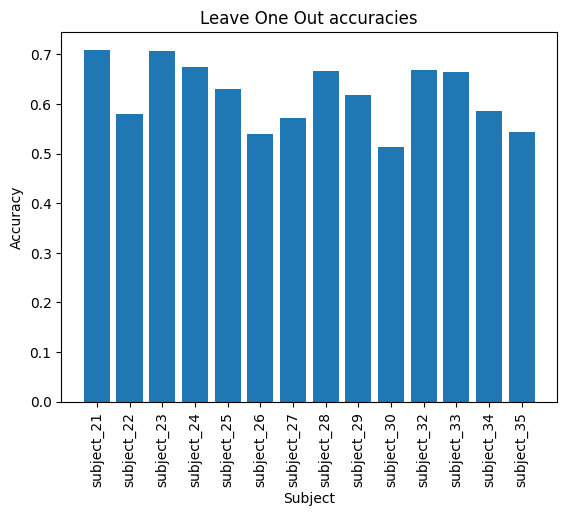

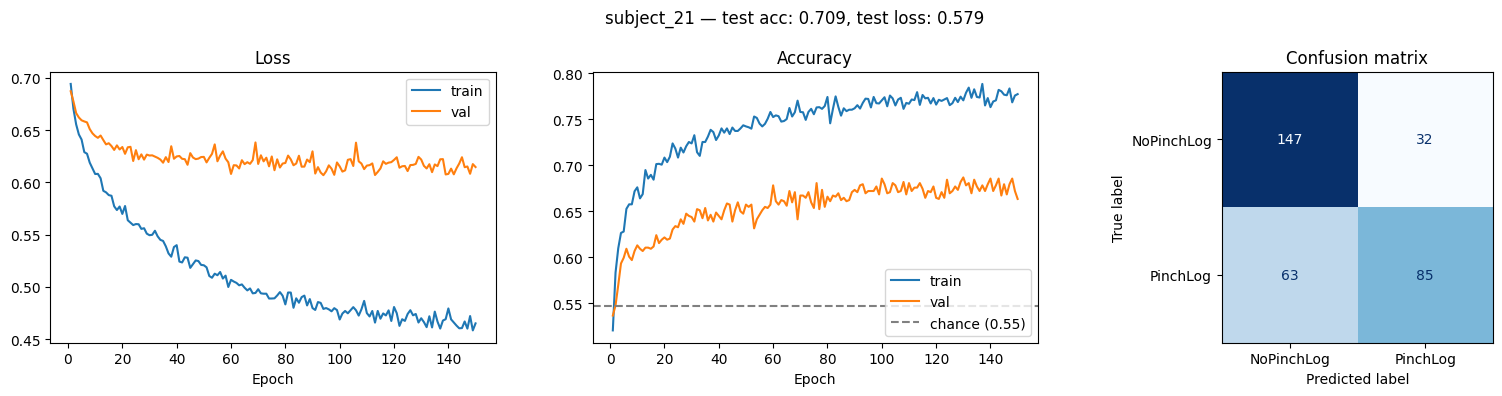

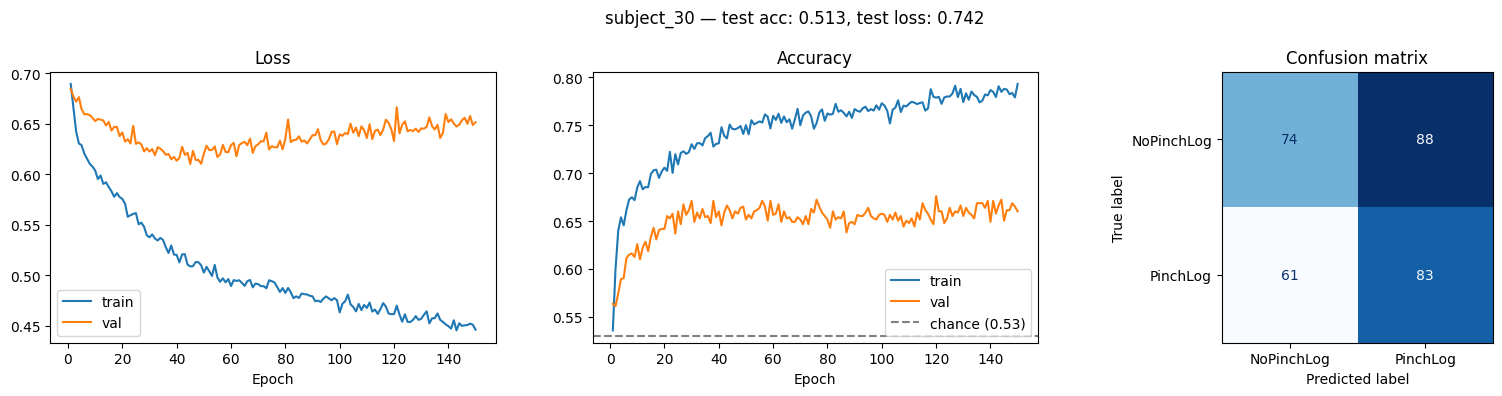

In [8]:
def plot_leave_one_out_run(results):
    plt.bar(results.keys(), [result['result']['test_accuracy'] for result in results.values()])
    plt.xlabel("Subject")
    plt.ylabel("Accuracy")
    plt.title("Leave One Out accuracies")
    plt.xticks(rotation=90)
    plt.show()

    best_subject = max(results, key=lambda k: results[k]['result']['test_accuracy'])
    worst_subject = min(results, key=lambda k: results[k]['result']['test_accuracy'])

    plot_run(results[best_subject]['result'], run_name=best_subject)
    plot_run(results[worst_subject]['result'], run_name=worst_subject)

plot_leave_one_out_run(results_leave_one_out)

### Comparing with hard-negatives

## Multi-Branch GAT-GRU-Transformer

Wang Z and Wang Y (2025)

Input:

In [9]:
# region Multi-Branch GAT-GRU-Transformer implementation

"""
Multi-Branch GAT-GRU-Transformer for EEG motor imagery.

Reimplementation of Wang, Z. & Wang, Y. (2025), "Multi-branch GAT-GRU-transformer
for explainable EEG-based finger motor imagery classification", Front. Hum.
Neurosci. 19:1599960.

    result = train_gat_gru_transformer(epochs_train, y_train, epochs_test, y_test)

X may be an mne.Epochs object or a (n_trials, n_channels, n_times) array. With
Epochs, the sampling rate, channel names and electrode positions are read from
`info`, so the distance-based graph works without a hand-maintained montage table.
Epochs are converted with the notebook's `_to_array` when it is in scope.

Architecture (paper sections 2.3-2.4):

    x : (N, C, T)
      |
    +-+--------------------+---------------------+
  spatial               temporal              frequency
  hierarchical GAT      GRU -> Transformer    FIR bank -> one
  over channels         + temporal attention  1-D CNN per band
      |                     |                     |
      +--- concat tokens ---+---------------------+
                    |
        1-D CNN head -> global avg pool -> FC(n_classes)
"""

from __future__ import annotations

import math
import time
import warnings
from typing import Any, Dict, List, Optional, Sequence, Tuple, Union

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.signal import butter, filtfilt, firwin, hilbert
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

# Physiological bands of paper section 2.3.3.
BANDS: Dict[str, Tuple[float, float]] = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 100.0),
}


# =============================================================================
# Input handling: mne.Epochs or ndarray
# =============================================================================
def _unpack(X, name: str = "X") -> Tuple[np.ndarray, Any]:
    """
    Returns (array (N, C, T), mne.Info or None).

    Epochs go through the notebook's `_to_array` when it exists, so whatever
    scaling or channel picking it does is applied consistently.
    """
    if hasattr(X, "get_data") and hasattr(X, "info"):          # mne.Epochs
        data = _to_array(X)
        return np.asarray(data, dtype=np.float32), X.info

    x = np.asarray(X.detach().cpu() if isinstance(X, torch.Tensor) else X,
                   dtype=np.float32)
    if x.ndim != 3:
        raise ValueError(f"{name} must be (n_trials, n_channels, n_times); got {x.shape}")
    if x.shape[1] > x.shape[2]:
        warnings.warn(f"{name} looks like (n_trials, n_times, n_channels); transposing")
        x = np.transpose(x, (0, 2, 1))
    return x, None


def _montage(info, n_channels: int) -> Tuple[List[str], Optional[np.ndarray]]:
    """Channel names and 3-D electrode positions from an mne.Info."""
    if info is None:
        return [f"ch{i}" for i in range(n_channels)], None

    names = list(info["ch_names"])
    pos = np.array([ch["loc"][:3] for ch in info["chs"]], dtype=float)
    if pos.shape[0] != n_channels or not np.isfinite(pos).all() or np.allclose(pos, 0):
        montage = info.get_montage() if hasattr(info, "get_montage") else None
        ch_pos = montage.get_positions().get("ch_pos", {}) if montage else {}
        pos = np.array([ch_pos.get(n, [np.nan] * 3) for n in names], dtype=float)
        if not np.isfinite(pos).all():
            warnings.warn("no usable electrode positions in info; "
                          "distance-based graphs unavailable")
            pos = None
    return names, pos


def _encode_labels(y_train, y_test):
    """Map arbitrary labels onto 0..K-1; returns (y_train, y_test, classes)."""
    to_np = lambda y: np.asarray(
        y.detach().cpu() if isinstance(y, torch.Tensor) else y).ravel()
    y_train, y_test = to_np(y_train), to_np(y_test)
    classes = np.unique(np.concatenate([y_train, y_test]))
    lut = {c: i for i, c in enumerate(classes)}
    enc = lambda y: np.array([lut[v] for v in y], dtype=np.int64)
    return enc(y_train), enc(y_test), classes


def _bands_for(sfreq: float) -> Dict[str, Tuple[float, float]]:
    """
    Bands clipped to what the sampling rate can represent.

    The paper band-passes to 100 Hz then resamples to 128 Hz, which puts Nyquist at
    64 Hz — its own gamma band is unobservable in the data the model sees. At 300 Hz
    there is no such problem; the clipping is here so lower rates degrade instead of
    throwing a filter-design error.
    """
    nyq = sfreq / 2.0
    return {name: (lo, min(hi, 0.9 * nyq)) for name, (lo, hi) in BANDS.items()
            if min(hi, 0.9 * nyq) > lo}


# =============================================================================
# PLV and the GAT adjacency (sections 2.3.1 / 2.5.2)
# =============================================================================

def _bandpass(x: np.ndarray, lo: float, hi: float, sfreq: float, order: int = 4):
    nyq = sfreq / 2.0
    b, a = butter(order, [max(lo, 1e-3) / nyq, min(hi, 0.99 * nyq) / nyq], btype="band")
    return filtfilt(b, a, x, axis=-1,
                    padlen=min(3 * max(len(a), len(b)), x.shape[-1] - 1))


def compute_plv(epochs: np.ndarray, sfreq: float, band: Tuple[float, float],
                max_trials: int = 500) -> np.ndarray:
    """
    Equation 8: PLV_ij = | (1/T) sum_t exp(i (phi_i - phi_j)) |, averaged over
    trials, with phases from the analytic (Hilbert) signal. (N, C, T) -> (C, C).
    """
    if len(epochs) > max_trials:
        idx = np.random.default_rng(0).choice(len(epochs), max_trials, replace=False)
        epochs = epochs[idx]
    filtered = _bandpass(epochs.astype(np.float64), band[0], band[1], sfreq)
    z = np.exp(1j * np.angle(hilbert(filtered, axis=-1)))
    return np.abs(np.einsum("nct,ndt->ncd", z, np.conj(z)) / z.shape[-1]).mean(0).real


def _topk_graph(weights: np.ndarray, degree: int) -> np.ndarray:
    """Keep the `degree` strongest edges per node, symmetrise, add self-loops."""
    C = weights.shape[0]
    w = weights.astype(float).copy()
    np.fill_diagonal(w, -np.inf)
    idx = np.argsort(-w, axis=1)[:, : int(np.clip(degree, 1, C - 1))]
    adj = np.zeros((C, C), dtype=bool)
    np.put_along_axis(adj, idx, True, axis=1)
    adj |= adj.T
    np.fill_diagonal(adj, True)
    return adj


def build_adjacency(train_epochs: np.ndarray, sfreq: float, kind: str = "plv",
                    degree: int = 6, positions: Optional[np.ndarray] = None
                    ) -> np.ndarray:
    """
    The GAT graph (section 2.3.1).

    "plv"      — PLV averaged across bands, the paper's biologically informed prior.
    "distance" — the paper's alternative, connecting nearby electrodes. Built as a
                 k-nearest-neighbour graph over the MNE positions rather than a fixed
                 distance d, so it does not depend on the montage's units or scale.
    "dense"    — every channel connected to every other.
    """
    C = train_epochs.shape[1]
    if kind == "dense":
        return np.ones((C, C), dtype=bool)
    if kind == "distance":
        if positions is None:
            warnings.warn("no electrode positions available; using a PLV graph")
        else:
            d = np.linalg.norm(positions[:, None] - positions[None, :], axis=-1)
            return _topk_graph(-d, degree)
    plv = np.mean([compute_plv(train_epochs, sfreq, band)
                   for band in _bands_for(sfreq).values()], axis=0)
    return _topk_graph(plv, degree)


# =============================================================================
# Blocks
# =============================================================================

class GATLayer(nn.Module):
    """
    Velickovic et al. (2018) graph attention, dense masked form:

        e_ij = LeakyReLU(a^T [W h_i || W h_j]),  alpha_i = softmax_j(e_ij),
        h'_i = sum_j alpha_ij W h_j

    Heads are concatenated when `concat`, else averaged. Attention is cached for
    the interpretability helpers.
    """

    def __init__(self, in_dim: int, out_dim: int, heads: int, concat: bool = True,
                 dropout: float = 0.4):
        super().__init__()
        self.concat, self.dropout = concat, dropout
        self.W = nn.Parameter(torch.empty(heads, in_dim, out_dim))
        self.a_src = nn.Parameter(torch.empty(heads, out_dim))
        self.a_dst = nn.Parameter(torch.empty(heads, out_dim))
        self.last_attention: Optional[torch.Tensor] = None
        nn.init.xavier_uniform_(self.W, gain=1.414)
        nn.init.xavier_uniform_(self.a_src.unsqueeze(0), gain=1.414)
        nn.init.xavier_uniform_(self.a_dst.unsqueeze(0), gain=1.414)

    def forward(self, h: torch.Tensor, adj: torch.Tensor) -> torch.Tensor:
        """h: (B, C, in_dim), adj: (C, C) bool -> (B, C, heads*out | out)"""
        Wh = torch.einsum("bci,hio->bhco", h, self.W)
        src = (Wh * self.a_src[None, :, None]).sum(-1)
        dst = (Wh * self.a_dst[None, :, None]).sum(-1)
        e = F.leaky_relu(src.unsqueeze(-1) + dst.unsqueeze(-2), 0.2)
        e = e.masked_fill(~adj.bool()[None, None], torch.finfo(e.dtype).min)

        alpha = torch.softmax(e, dim=-1)
        self.last_attention = alpha.detach()
        out = torch.einsum("bhij,bhjo->bhio",
                           F.dropout(alpha, self.dropout, self.training), Wh)
        return out.permute(0, 2, 1, 3).flatten(2) if self.concat else out.mean(1)


class SpatialBranch(nn.Module):
    """
    Section 2.3.1, hierarchical GAT: a low-level layer (heads concatenated) for local
    inter-channel interactions, a high-level layer (heads averaged) for global
    cross-region patterns.

    The paper does not say how a channel's time course becomes a node feature, so a
    weight-shared 1-D CNN does it. Its equations 1 and 2 also give the low-level
    output as (C x D) but the high-level one as (C x T x D), which cannot both hold
    for stacked GAT layers; both are (C x D) here and the time axis lives in the
    temporal branch.
    """

    def __init__(self, d_model: int, heads: int, dropout: float):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 16, 7, stride=2, padding=3), nn.BatchNorm1d(16), nn.ELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ELU(),
            nn.AdaptiveAvgPool1d(4), nn.Flatten(),
            nn.Linear(128, 64), nn.ELU(), nn.Dropout(dropout),
        )
        low_dim = max(8, d_model // heads)
        self.low = GATLayer(64, low_dim, heads, concat=True, dropout=dropout)
        self.high = GATLayer(low_dim * heads, d_model, max(1, heads // 2),
                             concat=False, dropout=dropout)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor, adj: torch.Tensor) -> torch.Tensor:
        """x: (B, C, T) -> (B, C, d_model): one token per electrode."""
        B, C, T = x.shape
        h = self.encoder(x.reshape(B * C, 1, T)).reshape(B, C, -1)
        h = F.elu(self.low(h, adj))
        return self.norm(F.elu(self.high(h, adj)))


class TemporalBranch(nn.Module):
    """
    Section 2.3.2: a unidirectional GRU for short-range dynamics, then a Transformer
    encoder for long-range ones. The "learnable temporal embedding vectors [that]
    dynamically weight the importance of different time points" are an additive
    positional embedding plus a learned query giving one softmax weight per step.
    `use_transformer=False` is the Table 5 GRU-only ablation.
    """

    def __init__(self, n_channels: int, n_times: int, d_model: int, heads: int,
                 dropout: float, use_transformer: bool = True, n_tokens: int = 16):
        super().__init__()
        stride = max(1, math.ceil(n_times / 256))     # keep the sequence manageable
        self.stem = nn.Sequential(
            nn.Conv1d(n_channels, d_model, 7, stride=stride, padding=3),
            nn.BatchNorm1d(d_model), nn.ELU())
        self.gru = nn.GRU(d_model, d_model, batch_first=True)

        self.time_embed = nn.Parameter(torch.zeros(1, n_times // stride + 1, d_model))
        nn.init.trunc_normal_(self.time_embed, std=0.02)
        self.query = nn.Parameter(torch.randn(d_model) / math.sqrt(d_model))
        self.last_weights: Optional[torch.Tensor] = None

        self.encoder = None
        if use_transformer:
            layer = nn.TransformerEncoderLayer(d_model, heads, 2 * d_model, dropout,
                                               activation="gelu", batch_first=True,
                                               norm_first=True)
            self.encoder = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.pool = nn.AdaptiveAvgPool1d(n_tokens)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, C, T) -> (B, n_tokens + 1, d_model)"""
        h, _ = self.gru(self.stem(x).transpose(1, 2))
        if self.encoder is not None:
            h = self.encoder(h + self.time_embed[:, : h.size(1)])
        h = self.drop(self.norm(h))

        w = torch.softmax((h @ self.query) / math.sqrt(h.size(-1)), dim=-1)
        self.last_weights = w.detach()
        pooled = torch.einsum("bl,bld->bd", w, h)
        tokens = self.pool((h * w.unsqueeze(-1) * h.size(1)).transpose(1, 2)).transpose(1, 2)
        return torch.cat([tokens, pooled.unsqueeze(1)], dim=1)


class FrequencyBranch(nn.Module):
    """
    Section 2.3.3: the signal is split into physiological bands and each gets its own
    1-D CNN (kernels 5/3/3, stride 1, ReLU, max pool); outputs are concatenated
    (equation 5). The filter bank is a frozen FIR layer inside the graph, so gradient
    and SHAP attributions run end to end from the raw epoch. Filter length is capped
    at half the epoch, which bounds how sharply delta can be separated.
    """

    def __init__(self, n_channels: int, n_times: int, sfreq: float, d_model: int,
                 dropout: float, n_tokens: int = 4):
        super().__init__()
        bands = _bands_for(sfreq)
        self.band_names = list(bands)
        numtaps = int(min(129, max(15, n_times // 2))) | 1
        nyq = sfreq / 2.0
        taps = [firwin(numtaps, [lo / nyq, min(hi, 0.99 * nyq) / nyq],
                       pass_zero=False, window="hamming") for lo, hi in bands.values()]
        self.register_buffer("taps", torch.tensor(np.stack(taps), dtype=torch.float32))
        self.pad = numtaps // 2

        def cnn():
            layers, in_ch = [], n_channels
            for out_ch, k in zip((d_model, d_model, d_model), (5, 3, 3)):
                layers += [nn.Conv1d(in_ch, out_ch, k, padding=k // 2),
                           nn.BatchNorm1d(out_ch), nn.ReLU(inplace=True),
                           nn.MaxPool1d(4), nn.Dropout(dropout)]
                in_ch = out_ch
            return nn.Sequential(*layers, nn.AdaptiveMaxPool1d(n_tokens))

        self.cnns = nn.ModuleList([cnn() for _ in self.band_names])
        self.band_embed = nn.Parameter(torch.zeros(len(self.band_names), d_model))
        nn.init.trunc_normal_(self.band_embed, std=0.02)

    def filter_bank(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, C, T) -> (B, n_bands, C, T)"""
        B, C, T = x.shape
        y = F.conv1d(x.reshape(B * C, 1, T), self.taps.unsqueeze(1), padding=self.pad)
        return y.reshape(B, C, len(self.band_names), -1).permute(0, 2, 1, 3)[..., :T]

    def forward(self, x: torch.Tensor,
                x_bands: Optional[torch.Tensor] = None) -> torch.Tensor:
        if x_bands is None:
            x_bands = self.filter_bank(x)
        return torch.cat([cnn(x_bands[:, i]).transpose(1, 2) + self.band_embed[i]
                          for i, cnn in enumerate(self.cnns)], dim=1)


# =============================================================================
# Model
# =============================================================================

class MultiBranchGATGRUTransformer(nn.Module):
    """
    Spatial (GAT) + temporal (GRU -> Transformer) + frequency (multi-band 1-D CNN)
    branches. Each emits `d_model`-wide tokens; these are concatenated, passed
    through a 1-D CNN and reduced by global average pooling (equations 6-7).
    """

    def __init__(self, n_channels: int, n_times: int, n_classes: int, sfreq: float,
                 adjacency: Optional[np.ndarray] = None, d_model: int = 32,
                 gat_heads: int = 4, dropout: float = 0.4, use_gat: bool = True,
                 use_transformer: bool = True, use_freq: bool = True):
        super().__init__()
        if not (use_gat or use_transformer or use_freq):
            raise ValueError("at least one branch must be enabled")
        self.n_channels, self.n_times, self.sfreq = n_channels, n_times, sfreq
        self.n_classes = n_classes

        adj = (np.ones((n_channels,) * 2, bool) if adjacency is None
               else np.asarray(adjacency, bool))
        if adj.shape != (n_channels, n_channels):
            raise ValueError(f"adjacency {adj.shape} does not match {n_channels} channels")
        self.register_buffer("adj", torch.tensor(adj))

        self.spatial = SpatialBranch(d_model, gat_heads, dropout) if use_gat else None
        self.temporal = TemporalBranch(n_channels, n_times, d_model, gat_heads,
                                       dropout, use_transformer)
        self.frequency = (FrequencyBranch(n_channels, n_times, sfreq, d_model, dropout)
                          if use_freq else None)

        self.head = nn.Sequential(nn.Conv1d(d_model, 2 * d_model, 3, padding=1),
                                  nn.BatchNorm1d(2 * d_model), nn.ELU(), nn.Dropout(dropout))
        self.classifier = nn.Sequential(nn.Dropout(0.6),
                                        nn.Linear(2 * d_model, n_classes))

    def forward(self, x: torch.Tensor,
                x_bands: Optional[torch.Tensor] = None) -> torch.Tensor:
        """x: (B, C, T) -> logits (B, n_classes)"""
        tokens = []
        if self.spatial is not None:
            tokens.append(self.spatial(x, self.adj))
        tokens.append(self.temporal(x))
        if self.frequency is not None:
            tokens.append(self.frequency(x, x_bands))
        return self.classifier(self.head(torch.cat(tokens, 1).transpose(1, 2)).mean(-1))

    def n_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


# =============================================================================
# Training
# =============================================================================

class _Dataset(torch.utils.data.Dataset):
    def __init__(self, x, y):
        self.x = torch.as_tensor(np.ascontiguousarray(x), dtype=torch.float32)
        self.y = torch.as_tensor(np.ascontiguousarray(y), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


@torch.no_grad()
def _evaluate(model, loader, device, criterion=None) -> Dict[str, Any]:
    model.eval()
    logits_all, y_all, loss_sum, n = [], [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        if criterion is not None:
            loss_sum += criterion(logits, yb).item() * len(yb)
        n += len(yb)
        logits_all.append(logits.float().cpu())
        y_all.append(yb.cpu())

    logits, y = torch.cat(logits_all), torch.cat(y_all).numpy()
    proba = torch.softmax(logits, 1).numpy()
    pred = proba.argmax(1)
    return {"loss": loss_sum / max(n, 1), "acc": float(accuracy_score(y, pred)),
            "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
            "y_true": y, "y_pred": pred, "proba": proba}

def train_gat_gru_transformer(
    X_train, y_train, X_test, y_test, *,
    sfreq: float = 300.0,
    run_name: Optional[str] = None,
    wandb_group: Optional[str] = None,
    wandb_tags: Optional[list] = None,
    log_wandb: bool = True,
    # architecture
    d_model: int = 32,
    gat_heads: int = 4,
    dropout: float = 0.4,
    adjacency: Union[str, np.ndarray] = "plv",
    graph_degree: int = 6,
    use_gat: bool = True,
    use_transformer: bool = True,
    use_freq: bool = True,
    # optimisation
    epochs: int = 200,
    batch_size: int = 64,
    lr: float = 1e-3,
    weight_decay: float = 1e-2,
    val_size: float = 0.1,
    seed: int = 42,
    device: Optional[str] = None,
    verbose: int = 1,
) -> Dict[str, Any]:
    """
    Train the Multi-Branch GAT-GRU-Transformer and evaluate it on the test set.

    X_train / X_test may be mne.Epochs or (n_trials, n_channels, n_times) arrays;
    with Epochs the sampling rate, channel names and electrode positions come from
    `info` and the `sfreq` argument is ignored. Labels may be of any type and come
    back in their original values.

    Knobs: `d_model` (width of every branch), `gat_heads`, `dropout`, `adjacency`
    ("plv", "distance", "dense", or a boolean matrix), `graph_degree` (edges kept
    per node), and `use_gat` / `use_transformer` / `use_freq` for the Table 5
    ablations.

    Returns a dict with the trained model, per-epoch history, test accuracy,
    predictions, probabilities and the confusion matrix (keys: model, history,
    test_accuracy, y_pred, y_proba, confusion_matrix; plus y_true, classes,
    ch_names, positions, adjacency, test_loss, test_macro_f1, best_epoch,
    n_parameters, training_time, run).
    """
    t0 = time.time()
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    # ---- data ---------------------------------------------------------------
    x_tr, info = _unpack(X_train, "X_train")
    x_te, _ = _unpack(X_test, "X_test")
    if x_tr.shape[1:] != x_te.shape[1:]:
        raise ValueError(f"train/test shapes differ: {x_tr.shape[1:]} vs {x_te.shape[1:]}")
    if info is not None:
        sfreq = float(info["sfreq"])

    y_tr, y_te, classes = _encode_labels(y_train, y_test)
    n_channels, n_times = x_tr.shape[1], x_tr.shape[2]
    ch_names, positions = _montage(info, n_channels)

    if val_size > 0:
        strat = y_tr if np.bincount(y_tr).min() >= 2 else None
        x_fit, x_va, y_fit, y_va = train_test_split(x_tr, y_tr, test_size=val_size,
                                                    stratify=strat, random_state=seed)
    else:
        x_fit, y_fit, x_va, y_va = x_tr, y_tr, None, None

    # Built on the training split only, so the graph leaks nothing.
    adj = (build_adjacency(x_fit, sfreq, adjacency, graph_degree, positions)
           if isinstance(adjacency, str) else np.asarray(adjacency, bool))

    # ---- model --------------------------------------------------------------
    model = MultiBranchGATGRUTransformer(
        n_channels, n_times, len(classes), sfreq, adj, d_model=d_model,
        gat_heads=gat_heads, dropout=dropout, use_gat=use_gat,
        use_transformer=use_transformer, use_freq=use_freq).to(device)
    if verbose:
        print(f"[model] {model.n_parameters():,} parameters on {device} | "
              f"{n_channels} ch x {n_times} samples @ {sfreq:g} Hz | "
              f"{len(classes)} classes | graph density {adj.mean():.2f}")

    # ---- wandb --------------------------------------------------------------
    run = wandb_start_run("gat_gru_transformer", run_name=run_name, group=wandb_group,
                tags=wandb_tags, enabled=log_wandb,
                config=dict(sfreq=sfreq, n_channels=n_channels, n_times=n_times,
                            n_classes=len(classes), d_model=d_model,
                            gat_heads=gat_heads, dropout=dropout,
                            adjacency=str(adjacency)[:32],
                            graph_degree=graph_degree, use_gat=use_gat,
                            use_transformer=use_transformer, use_freq=use_freq,
                            epochs=epochs, batch_size=batch_size, lr=lr,
                            weight_decay=weight_decay, seed=seed,
                            n_train=len(x_fit), n_test=len(x_te),
                            n_parameters=model.n_parameters()))

    try:
        mk = lambda x, y, sh: torch.utils.data.DataLoader(
            _Dataset(x, y), batch_size=batch_size, shuffle=sh,
            drop_last=sh and len(y) > batch_size)
        tr_loader = mk(x_fit, y_fit, True)
        va_loader = mk(x_va, y_va, False) if y_va is not None else None
        te_loader = mk(x_te, y_te, False)

        counts = np.bincount(y_fit, minlength=len(classes)).astype(np.float32)
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(
            counts.sum() / (len(classes) * np.maximum(counts, 1)), device=device),
            label_smoothing=0.1)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

        history = {"loss": [], "acc": [], "val_loss": [], "val_acc": [],
                    "lr": [], "epoch_time": [], "val_macro_f1": []}
        best_score, best_state, best_epoch = -np.inf, None, 0
        for epoch in range(1, epochs + 1):
            model.train()
            t_epoch, run_loss, correct, n = time.time(), 0.0, 0, 0
            for xb, yb in tr_loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(set_to_none=True)
                logits = model(xb)
                loss = criterion(logits, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                run_loss += loss.item() * len(yb)
                correct += int((logits.argmax(1) == yb).sum())
                n += len(yb)
            sched.step()

            history["loss"].append(run_loss / max(n, 1))
            history["acc"].append(correct / max(n, 1))
            history["lr"].append(opt.param_groups[0]["lr"])
            history["epoch_time"].append(time.time() - t_epoch)

            if va_loader is not None:
                va = _evaluate(model, va_loader, device, criterion)
                history["val_loss"].append(va["loss"])
                history["val_acc"].append(va["acc"])
                history["val_macro_f1"].append(va["macro_f1"])

            score = history["val_acc"][-1] if va_loader is not None else history["acc"][-1]
            if score > best_score:
                best_score, best_epoch = score, epoch
                best_state = {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()}

            if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == epochs):
                msg = (f"epoch {epoch:4d}/{epochs} | "
                       f"train {history['loss'][-1]:.4f}/{history['acc'][-1]:.4f}")
                if va_loader is not None:
                    msg += f" | val {history['val_loss'][-1]:.4f}/{history['val_acc'][-1]:.4f}"
                print(msg + f" | {history['epoch_time'][-1]:.1f}s")

        if best_state is not None:
            model.load_state_dict(best_state)

        # ---- test ------------------------------------------------------------
        test = _evaluate(model, te_loader, device, criterion)
        labels, names = np.arange(len(classes)), [str(c) for c in classes]
        cm = confusion_matrix(test["y_true"], test["y_pred"], labels=labels)
        if verbose:
            print(f"\ntest accuracy {test['acc']:.4f} | macro-F1 {test['macro_f1']:.4f}"
                  f" | best epoch {best_epoch}")
            print(classification_report(test["y_true"], test["y_pred"], labels=labels,
                                        target_names=names, digits=4, zero_division=0))

        wandb_log_test_results(run, test_accuracy=test["acc"], y_true=classes[test["y_true"]],
                 y_pred=classes[test["y_pred"]], classes=names,
                 test_loss=test["loss"],
                 extra={"test_macro_f1": test["macro_f1"], "best_epoch": best_epoch,
                        "n_parameters": model.n_parameters()})

        return {"model": model, "history": history, "test_accuracy": test["acc"],
                "y_pred": classes[test["y_pred"]], "y_proba": test["proba"],
                "confusion_matrix": cm, "y_true": classes[test["y_true"]],
                "classes": classes, "ch_names": ch_names, "positions": positions,
                "adjacency": adj, "test_loss": test["loss"],
                "test_macro_f1": test["macro_f1"], "best_epoch": best_epoch,
                "n_parameters": model.n_parameters(),
                "training_time": time.time() - t0, "run": run}
    finally:
        wandb_finish_run(run)


@torch.no_grad()
def predict(model: MultiBranchGATGRUTransformer, X, classes=None,
            batch_size: int = 64):
    """Run a trained model on new epochs. Returns (labels, probabilities)."""
    x, _ = _unpack(X)

    device = next(model.parameters()).device
    model.eval()
    proba = np.concatenate([
        torch.softmax(model(torch.as_tensor(x[i:i + batch_size], device=device)), 1)
        .float().cpu().numpy() for i in range(0, len(x), batch_size)])
    idx = proba.argmax(1)
    return (classes[idx] if classes is not None else idx), proba


# =============================================================================
# Interpretability (paper section 2.5)
# =============================================================================

def channel_importance(model, X, y, ch_names: Sequence[str], top_k: int = 10,
                       batch_size: int = 32) -> List[Tuple[str, float]]:
    """
    Gradient x input attribution averaged per channel — the Figure 6A ranking. For
    true SHAP values, `shap.GradientExplainer(model, background)` works directly on
    this model; DeepExplainer does not, having no rule for the GRU and Transformer
    ops the paper's own model also contains.
    """
    x, _ = _unpack(X)
    device = next(model.parameters()).device
    model.eval()
    scores = np.zeros(x.shape[1])
    # eval-mode forward + backward through a cuDNN GRU raises "cudnn RNN backward
    # can only be called in training mode"; the non-cuDNN path has no such
    # restriction and costs nothing at this (attribution-only) scale.
    with torch.backends.cudnn.flags(enabled=False):
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[i:i + batch_size], device=device).requires_grad_(True)
            yb = torch.as_tensor(np.asarray(y[i:i + batch_size]), dtype=torch.long,
                                 device=device)
            model(xb).gather(1, yb[:, None]).sum().backward()
            scores += (xb.grad * xb).abs().mean(-1).sum(0).detach().cpu().numpy()
    scores /= max(len(x), 1)
    return [(ch_names[j], float(scores[j])) for j in np.argsort(-scores)[:top_k]]


def band_importance(model, X, y, batch_size: int = 32) -> Dict[str, float]:
    """
    Per-band importance (Figure 6B): gradient x input on the filter-bank output
    rather than on the raw signal. Needs the frequency branch.
    """
    if model.frequency is None:
        raise ValueError("model was built with use_freq=False")
    x, _ = _unpack(X)
    device = next(model.parameters()).device
    model.eval()
    totals = np.zeros(len(model.frequency.band_names))
    with torch.backends.cudnn.flags(enabled=False):
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[i:i + batch_size], device=device)
            yb = torch.as_tensor(np.asarray(y[i:i + batch_size]), dtype=torch.long,
                                 device=device)
            bands = model.frequency.filter_bank(xb).detach().requires_grad_(True)
            model(xb, x_bands=bands).gather(1, yb[:, None]).sum().backward()
            totals += ((bands.grad * bands).abs().mean((0, 2, 3)).detach().cpu().numpy()
                       * len(yb))
    return dict(zip(model.frequency.band_names, (totals / max(len(x), 1)).tolist()))


def gat_attention(model, X, ch_names: Sequence[str], top_k: int = 10,
                  batch_size: int = 64):
    """Mean incoming GAT attention per electrode — the learned spatial graph."""
    if model.spatial is None:
        raise ValueError("model was built with use_gat=False")
    x, _ = _unpack(X)
    device = next(model.parameters()).device
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            model(torch.as_tensor(x[i:i + batch_size], device=device))
            maps = [model.spatial.low.last_attention, model.spatial.high.last_attention]
            total = total + torch.stack([m.mean(1).mean(0) for m in maps]).mean(0)
            n += 1
    att = (total / max(n, 1)).cpu().numpy()
    incoming = att.mean(0)
    return [(ch_names[j], float(incoming[j])) for j in np.argsort(-incoming)[:top_k]], att


def plv_report(X, sfreq: float = 300.0, ch_names: Optional[Sequence[str]] = None,
               bands: Sequence[str] = ("alpha", "beta", "gamma"), top_k: int = 10):
    """Section 4.2 / Figure 7: strongest phase-synchronised channel pairs per band."""
    x, info = _unpack(X)
    if info is not None:
        sfreq, ch_names = float(info["sfreq"]), list(info["ch_names"])
    ch_names = list(ch_names or [f"ch{i}" for i in range(x.shape[1])])

    out = {}
    for name, band in _bands_for(sfreq).items():
        if name not in bands:
            continue
        plv = compute_plv(x, sfreq, band)
        iu = np.triu_indices_from(plv, k=1)
        vals = plv[iu]
        out[name] = [(ch_names[iu[0][j]], ch_names[iu[1][j]], float(vals[j]))
                     for j in np.argsort(-vals)[:top_k]]
    return out

# endregion

In [16]:
def transformer_general():
    X_train_idx, X_test_idx, y_train, y_test = train_test_split(np.arange(len(filtered_epochs_scaled)), filtered_epochs_scaled.metadata.EventType, test_size=.2)
    X_train, X_test = filtered_epochs_scaled[X_train_idx], filtered_epochs_scaled[X_test_idx]
    out = train_gat_gru_transformer(X_train, y_train, X_test, y_test, sfreq=300.0, epochs=15, batch_size=32, log_wandb=False)
    print("test accuracy:", out["test_accuracy"])
    print(out["confusion_matrix"])
    return out

def transformer_cross_subject(leave_out=''):
    train_subjects, test_subjects = train_test_split(filtered_epochs_scaled.metadata["subject"].unique().tolist())
    if leave_out != '':
        train_subjects = filtered_epochs_scaled.metadata["subject"].unique().tolist()
        train_subjects.remove(leave_out)
        test_subjects = [leave_out]

    print(f"{len(train_subjects)} train subjects, {len(test_subjects)} test subjects")

    train_epochs = query_epochs(filtered_epochs_scaled, f"subject in {train_subjects}")
    test_epochs = query_epochs(filtered_epochs_scaled, f"subject in {test_subjects}")

    return train_gat_gru_transformer(train_epochs, train_epochs.metadata.EventType, test_epochs, test_epochs.metadata.EventType, sfreq=300.0, epochs=15, batch_size=32, log_wandb=False, lr=1e-4), test_epochs.metadata

def transformer_leave_one_out():
    results = {}
    for subject in filtered_epochs_scaled.metadata["subject"].unique().tolist():
        result, metadata = transformer_cross_subject(leave_out=subject)
        results[subject] = {
            'result': result,
            'test_metadata': metadata
        }
    return results

transformer_general_run = run_cached("transformer_general_run", transformer_general)
transformer_leave_one_out_run = run_cached("transformer_leave_one_out_run", transformer_leave_one_out)

[transformer_general_run] forced recompute, running...
[model] 99,362 parameters on cuda | 20 ch x 601 samples @ 300 Hz | 2 classes | graph density 0.40
epoch    1/15 | train 0.6832/0.5568 | val 0.6659/0.6080 | 1.8s
epoch   10/15 | train 0.4818/0.8151 | val 0.7803/0.6136 | 1.6s
epoch   15/15 | train 0.4193/0.8642 | val 0.8287/0.6335 | 1.6s

test accuracy 0.6200 | macro-F1 0.6192 | best epoch 6
              precision    recall  f1-score   support

  NoPinchLog     0.6511    0.6234    0.6370       470
    PinchLog     0.5874    0.6161    0.6014       409

    accuracy                         0.6200       879
   macro avg     0.6193    0.6198    0.6192       879
weighted avg     0.6215    0.6200    0.6204       879

test accuracy: 0.6200227531285551
[[293 177]
 [157 252]]
[transformer_leave_one_out_run] forced recompute, running...
13 train subjects, 1 test subjects
[model] 99,362 parameters on cuda | 20 ch x 601 samples @ 300 Hz | 2 classes | graph density 0.39
epoch    1/15 | train 0.7

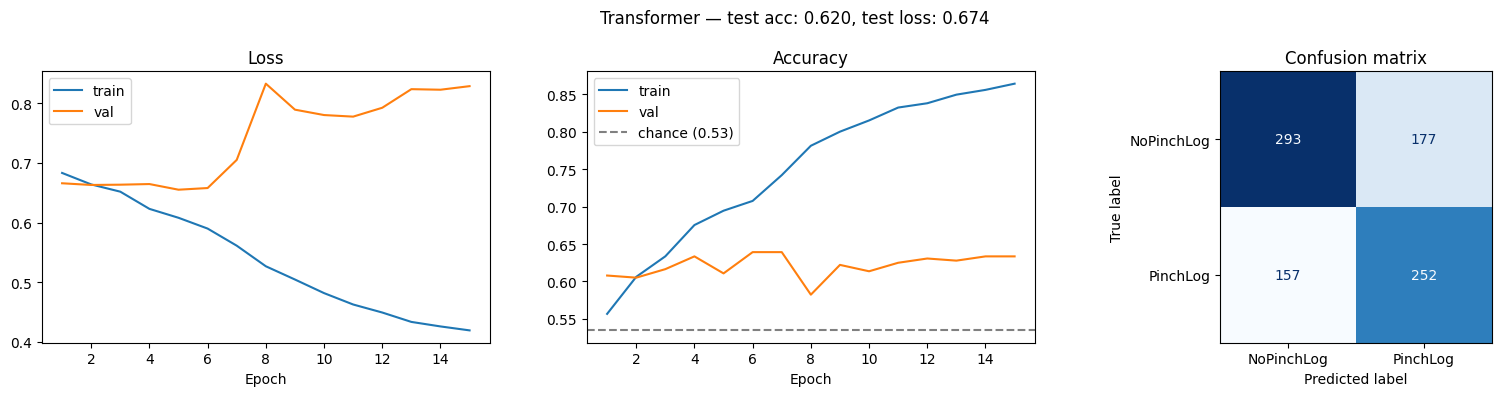

In [17]:
_ = plot_run(transformer_general_run, run_name="Transformer")

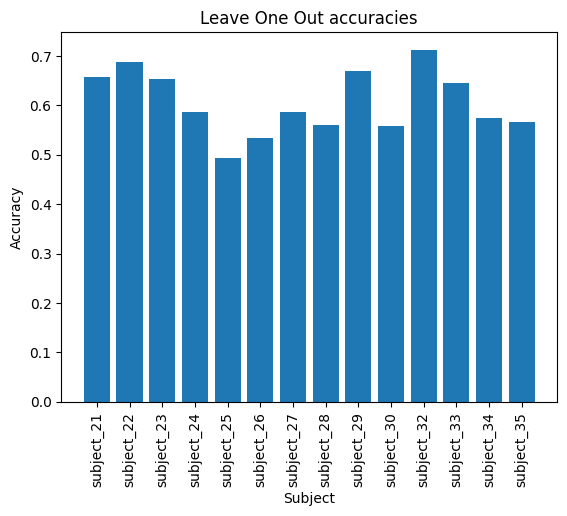

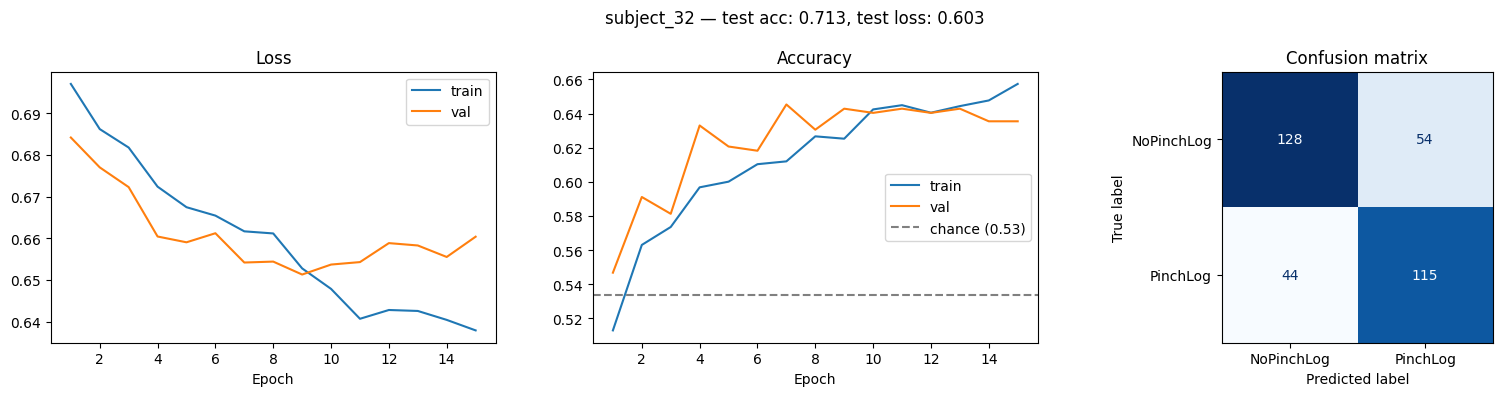

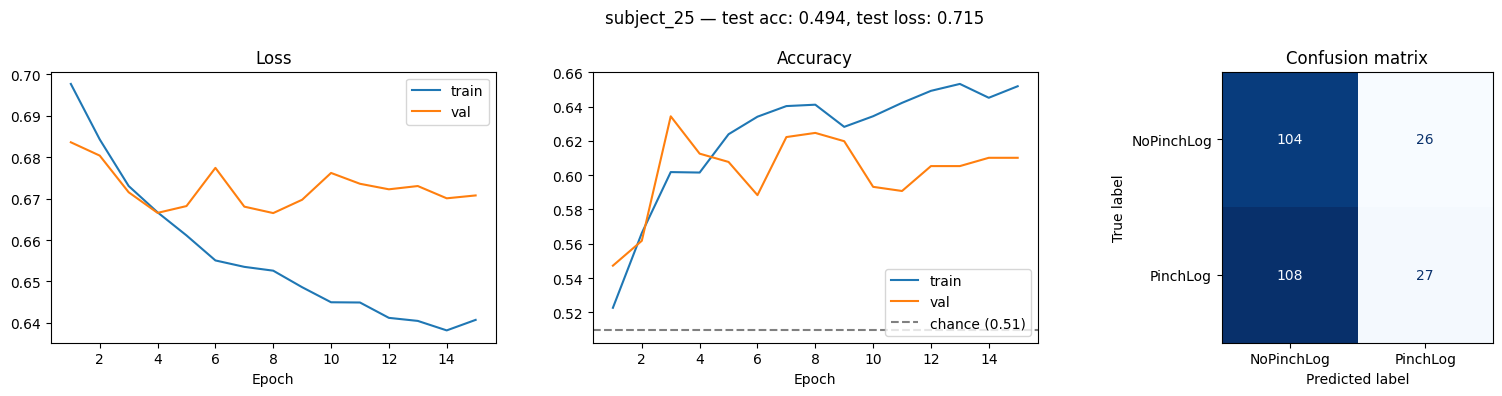

In [18]:
plot_leave_one_out_run(transformer_leave_one_out_run)
# transformer_leave_one_out_run['result']

### Model interpretability (paper section 2.5) — best leave-one-out subject

Runs the interpretability helpers defined in the Multi-Branch GAT-GRU-Transformer cell (`channel_importance`, `band_importance`, `gat_attention`, `plv_report`) on the leave-one-out fold with the highest held-out test accuracy.

In [19]:
best_subject = max(transformer_leave_one_out_run, key=lambda k: transformer_leave_one_out_run[k]['result']['test_accuracy'])
best_result = transformer_leave_one_out_run[best_subject]['result']
model = best_result['model']
ch_names = best_result['ch_names']
classes = best_result['classes']

test_epochs = query_epochs(filtered_epochs_scaled, f"subject in ['{best_subject}']")
lut = {c: i for i, c in enumerate(classes)}
y_enc = np.array([lut[v] for v in test_epochs.metadata.EventType.values])

print(f"best subject: {best_subject} | test accuracy {best_result['test_accuracy']:.4f} | "
      f"macro-F1 {best_result['test_macro_f1']:.4f} | {len(test_epochs)} held-out trials")

best subject: subject_32 | test accuracy 0.7126 | macro-F1 0.7122 | 341 held-out trials


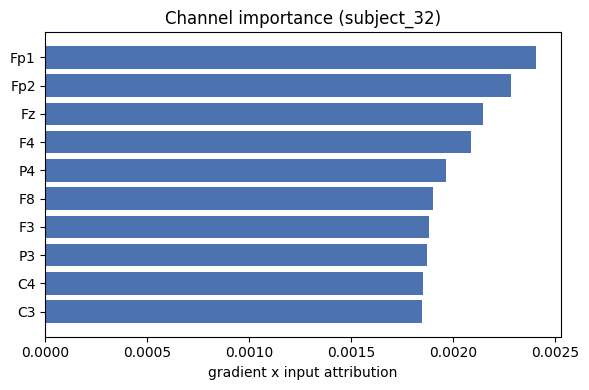

In [20]:
chan_imp = channel_importance(model, test_epochs, y_enc, ch_names, top_k=10)
plt.figure(figsize=(6, 4))
plt.barh([c for c, _ in chan_imp[::-1]], [v for _, v in chan_imp[::-1]], color="#4C72B0")
plt.xlabel("gradient x input attribution")
plt.title(f"Channel importance ({best_subject})")
plt.tight_layout()
plt.show()

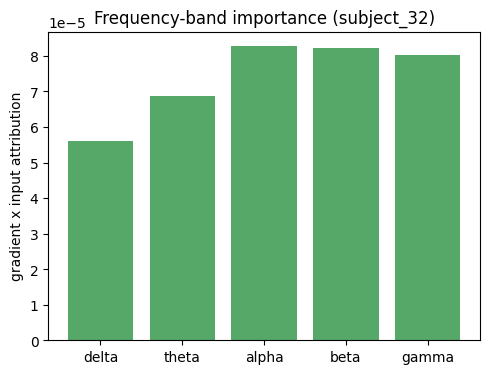

In [21]:
band_imp = band_importance(model, test_epochs, y_enc)
plt.figure(figsize=(5, 4))
plt.bar(list(band_imp.keys()), list(band_imp.values()), color="#55A868")
plt.ylabel("gradient x input attribution")
plt.title(f"Frequency-band importance ({best_subject})")
plt.tight_layout()
plt.show()

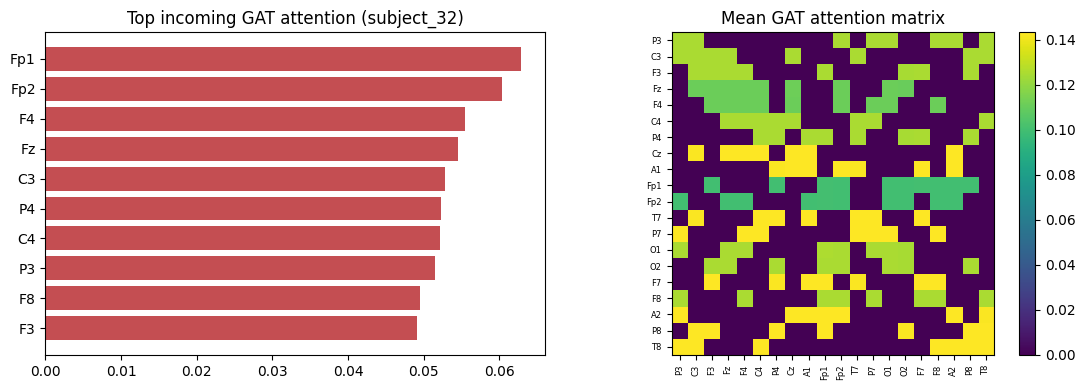

In [22]:
gat_top, gat_att = gat_attention(model, test_epochs, ch_names, top_k=10)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh([c for c, _ in gat_top[::-1]], [v for _, v in gat_top[::-1]], color="#C44E52")
axes[0].set_title(f"Top incoming GAT attention ({best_subject})")

im = axes[1].imshow(gat_att, cmap="viridis")
axes[1].set_xticks(range(len(ch_names))); axes[1].set_xticklabels(ch_names, rotation=90, fontsize=6)
axes[1].set_yticks(range(len(ch_names))); axes[1].set_yticklabels(ch_names, fontsize=6)
axes[1].set_title("Mean GAT attention matrix")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

In [23]:
plv = plv_report(test_epochs, sfreq=300.0, ch_names=ch_names, bands=("alpha", "beta", "gamma"))
for band, pairs in plv.items():
    print(f"{band}:")
    for a, b, v in pairs[:5]:
        print(f"  {a}-{b}: {v:.3f}")

alpha:
  Fz-F4: 0.718
  F4-Fp2: 0.682
  F3-Fz: 0.615
  Fz-Fp2: 0.594
  Cz-A1: 0.584
beta:
  F3-Fz: 0.618
  Fz-F4: 0.612
  F4-Fp2: 0.588
  Fp2-O1: 0.545
  Fp1-F7: 0.525
gamma:
  F3-Fz: 0.580
  Fp2-O1: 0.548
  Fz-F4: 0.530
  O1-O2: 0.526
  Fp1-F7: 0.510


## Analysing free variables

This chapter highlights differences in classification performance from a free variable standpoint.

In [24]:
results_general_meta

,UnityTimestamp,EventType,EventName,Severity,ExperimentName,ExperimentIndex,timestamp,stream,Eye,State,...,GazeDirection.z,HeadPosition.x,HeadPosition.y,HeadPosition.z,HeadForward.x,HeadForward.y,HeadForward.z,sample,subject,session
12557,2026-08-28T16:51:59.2376691+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment1 (Experiments.ExperimentStatic),1,71.950408,Experiment.VIBE.GameEventStream,None,None,...,0.997981,0.089596,1.105341,0.113163,-0.081380,0.121340,0.989269,72224,subject_24,session_2
20561,NaN,NoPinchLog,NaN,NaN,NaN,9,1033.501563,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,397380,subject_26,session_1
4742,2026-08-27T17:01:59.6619305+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment1 (Experiments.ExperimentStatic),1,38.037673,Experiment.VIBE.GameEventStream,None,None,...,0.996983,0.059416,1.100027,-0.059462,0.023728,0.072560,0.997082,57803,subject_22,session_2
9682,2026-08-28T16:17:39.1692957+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment4 (Experiments.ExperimentRandom),4,423.845785,Experiment.VIBE.GameEventStream,None,None,...,0.955336,0.165100,1.131406,0.265679,-0.068901,0.103832,0.992205,171820,subject_24,session_1
34757,NaN,NoPinchLog,NaN,NaN,NaN,6,680.978671,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,250419,subject_30,session_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7020,NaN,NoPinchLog,NaN,NaN,NaN,7,847.889624,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,307115,subject_23,session_1
48753,NaN,NoPinchLog,NaN,NaN,NaN,11,1318.049439,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,438619,subject_34,session_1
23750,NaN,NoPinchLog,NaN,NaN,NaN,7,770.130965,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,275707,subject_27,session_1
44723,2026-09-16T14:26:18.6126186+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment2 (Experiments.ExperimentStatic),2,150.968520,Experiment.VIBE.GameEventStream,None,None,...,0.995515,-0.016645,1.133958,-0.076513,0.024743,-0.023299,0.999422,92363,subject_33,session_2


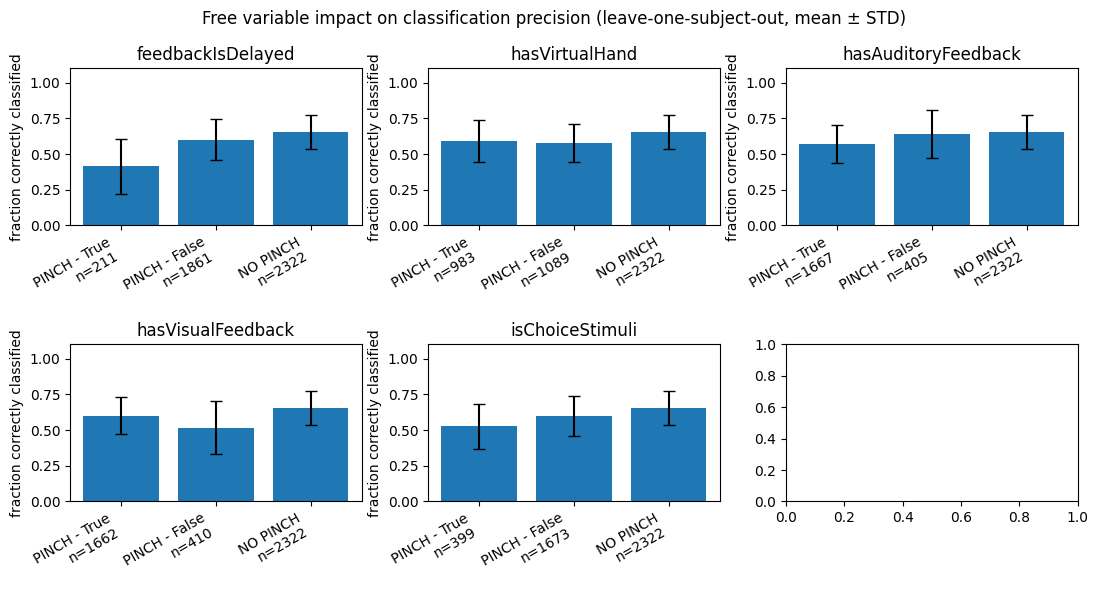

In [25]:
FREE_VARS = ['feedbackIsDelayed', 'hasVirtualHand', 'hasAuditoryFeedback', 'hasVisualFeedback', 'isChoiceStimuli']

def _loo_fold_metadata(payload):
    """Attaches y_pred and per-class probability columns to one leave-one-subject-out fold's test metadata."""
    result = payload["result"]
    meta = payload["test_metadata"].copy()
    meta["y_pred"] = result["y_pred"]
    classes = result["classes"]
    for i, c in enumerate(classes):
        meta[f"y_proba_{c}"] = result["y_proba"][:, i]
    meta["proba_true"] = np.where(
        meta["EventType"] == "PinchLog", meta["y_proba_PinchLog"], meta["y_proba_NoPinchLog"]
    )
    return meta

def _hardlabel_precision(metadata, v):
    """Fraction of correctly predicted labels per group, for one free variable."""
    def frac(hit_query, total_query):
        total = len(metadata.query(total_query))
        if total == 0:
            return np.nan, 0
        return len(metadata.query(hit_query)) / total, total

    pinch_true, n_true = frac(
        f"{v} == True & EventType == 'PinchLog' & y_pred == 'PinchLog'",
        f"{v} == True & EventType == 'PinchLog'",
    )
    pinch_false, n_false = frac(
        f"{v} == False & EventType == 'PinchLog' & y_pred == 'PinchLog'",
        f"{v} == False & EventType == 'PinchLog'",
    )
    no_pinch, n_no_pinch = frac(
        "EventType == 'NoPinchLog' & y_pred == 'NoPinchLog'",
        "EventType == 'NoPinchLog'",
    )
    return [pinch_true, pinch_false, no_pinch], [n_true, n_false, n_no_pinch]


def plot_free_variable_comparison_loo(results_leave_one_out, group_stat_fn, ylabel, title, agg="std"):
    """
    Aggregates a per-group statistic (computed per left-out subject via group_stat_fn) across
    leave-one-subject-out folds, and plots the across-fold mean with std/SEM error bars - this
    captures subject-to-subject variability that a single train/test split can't show.
    """
    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    axes = axes.flatten()

    for i, v in enumerate(FREE_VARS):
        fold_values, fold_ns = [], []
        for payload in results_leave_one_out.values():
            values, ns = group_stat_fn(_loo_fold_metadata(payload), v)
            fold_values.append(values)
            fold_ns.append(ns)

        values = np.array(fold_values, dtype=float)  # (n_folds, 3)
        ns = np.nansum(np.array(fold_ns, dtype=float), axis=0).astype(int)

        means = np.nanmean(values, axis=0)
        stds = np.nanstd(values, axis=0, ddof=1)
        n_folds = np.sum(~np.isnan(values), axis=0)
        errs = stds / np.sqrt(np.maximum(n_folds, 1)) if agg == "sem" else stds
        errs = np.nan_to_num(errs, nan=0.0)

        labels = [f"PINCH - True\nn={ns[0]}", f"PINCH - False\nn={ns[1]}", f"NO PINCH\nn={ns[2]}"]

        axes[i].bar(labels, means, yerr=errs, capsize=4)
        axes[i].set_title(v)
        axes[i].set_ylabel(ylabel)
        axes[i].tick_params(axis="x", rotation=30)
        axes[i].set_ylim((0, 1.1))
        for label in axes[i].get_xticklabels():
            label.set_ha("right")

    fig.suptitle(f"{title} (leave-one-subject-out, mean ± {agg.upper()})")
    fig.tight_layout()
    return fig


_ = plot_free_variable_comparison_loo(
    results_leave_one_out, _hardlabel_precision, ylabel="fraction correctly classified",
    title="Free variable impact on classification precision",
)

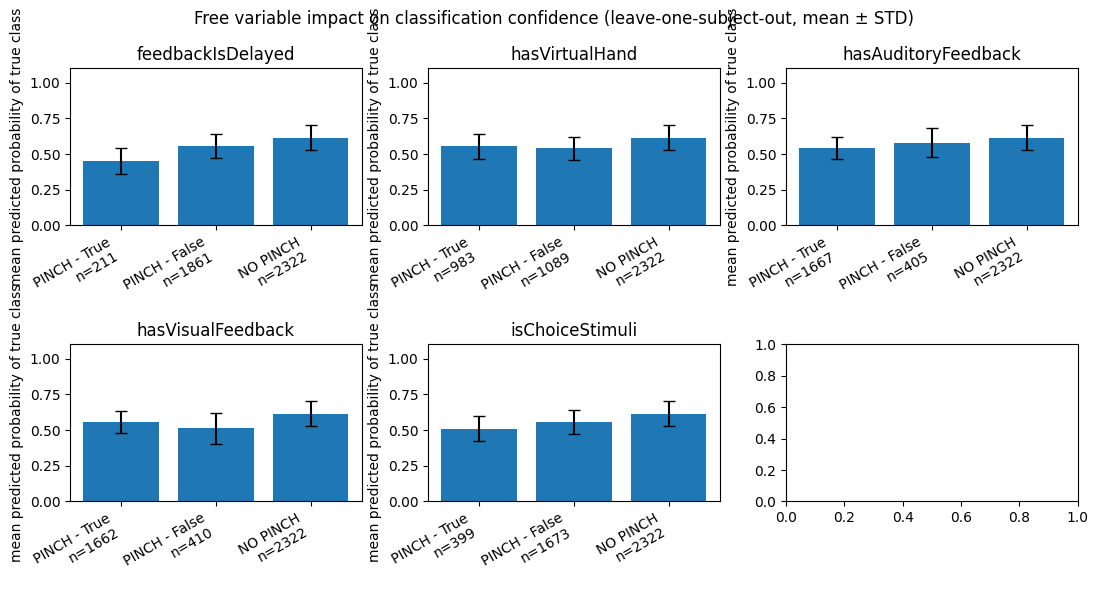

In [26]:
def _mean_true_proba(metadata, v):
    """Mean predicted probability assigned to the true class per group, for one free variable."""
    def mean_and_n(query):
        sub = metadata.query(query)
        if len(sub) == 0:
            return np.nan, 0
        return sub["proba_true"].mean(), len(sub)

    pinch_true, n_true = mean_and_n(f"{v} == True & EventType == 'PinchLog'")
    pinch_false, n_false = mean_and_n(f"{v} == False & EventType == 'PinchLog'")
    no_pinch, n_no_pinch = mean_and_n("EventType == 'NoPinchLog'")
    return [pinch_true, pinch_false, no_pinch], [n_true, n_false, n_no_pinch]


_ = plot_free_variable_comparison_loo(
    results_leave_one_out, _mean_true_proba, ylabel="mean predicted probability of true class",
    title="Free variable impact on classification confidence",
)

## Persist results

In [27]:
for path in sorted(RESULTS_DIR.glob("*.pkl")):
    with open(path, "rb") as fh:
        cached = pickle.load(fh)
    match = "current" if cached.get("data_version") == DATA_VERSION else "stale"
    print(f"{path.stem:30s} data_version={cached.get('data_version')} ({match})")


classify_leave_one_out4        data_version=a4190877a20981c4 (current)
results_cross_session          data_version=a4190877a20981c4 (current)
results_cross_subject          data_version=a4190877a20981c4 (current)
results_general                data_version=a4190877a20981c4 (current)
results_leave_one_out          data_version=a4190877a20981c4 (current)
results_leave_one_out1         data_version=a4190877a20981c4 (current)
results_leave_one_out2         data_version=a4190877a20981c4 (current)
results_leave_one_out3         data_version=a4190877a20981c4 (current)
transformer_general_run        data_version=a4190877a20981c4 (current)
transformer_leave_one_out_run  data_version=a4190877a20981c4 (current)
